In [2]:
import os
import cartopy.crs as ccrs
import cartopy.feature as cfeature
from cartopy.mpl.gridliner import LONGITUDE_FORMATTER, LATITUDE_FORMATTER
import cartopy.mpl.ticker as mticker
import xarray as xr
import cartopy 
import pandas as pd
import netCDF4 as nc
import numpy as np
from cftime import DatetimeNoLeap
import glob
import matplotlib.colors as colors
#import cdo as cd
import dask.array as da
import string
import datetime
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap
import mpl_toolkits as mpl
import calendar
from scipy import stats
import scipy.stats  as ss
import cftime
from scipy.stats import pearsonr

In [3]:
models=['ERA5','NCEP','Ensemble','ACCESS-CM2','ACCESS-ESM1-5','AWI-ESM-1-1-LR','BCC-ESM1','BCC-CSM2-MR','CAMS-CSM1-0','CESM2','CESM2-FV2','CMCC-ESM2','CMCC-CM2-SR5','CanESM5','EC-Earth3-CC','FGOALS-g3','HadGEM3-GC31-MM','GFDL-ESM4','GFDL-CM4','ITTM-ESM','INM-CM4-8','INM-CM5-0','IPSL-CM6A-LR','NESM3','MPI-ESM1-2-LR','MRI-ESM2-0','MIROC6','NorCPM1','NorESM2-LM','NorESM2-MM','TaiESM1','KACE-1-0-G']

In [4]:
centroid=xr.Dataset()

for i in models:
    centroid[i] = xr.open_dataset('/data/strato/jupyter/Ramugondo/Merged')[i].sel(lon=slice(5,55),lat=slice(-40,-5))
    

/Users/ntanganedzeniramugondo/Anacondanew1/envs/New_env/lib/python3.12/site-packages/xarray/backends/plugins.py:80: RuntimeWarning: Engine 'cfgrib' loading failed:
cannot load library '/usr/local/lib/libeccodes.dylib': dlopen(/usr/local/lib/libeccodes.dylib, 0x0002): tried: '/usr/local/lib/libeccodes.dylib' (mach-o file, but is an incompatible architecture (have 'x86_64', need 'arm64e' or 'arm64e.v1' or 'arm64' or 'arm64')), '/System/Volumes/Preboot/Cryptexes/OS/usr/local/lib/libeccodes.dylib' (no such file), '/usr/local/lib/libeccodes.dylib' (mach-o file, but is an incompatible architecture (have 'x86_64', need 'arm64e' or 'arm64e.v1' or 'arm64' or 'arm64')), '/usr/local/Cellar/eccodes/2.24.2_1/lib/libeccodes.dylib' (mach-o file, but is an incompatible architecture (have 'x86_64', need 'arm64e' or 'arm64e.v1' or 'arm64' or 'arm64')), '/System/Volumes/Preboot/Cryptexes/OS/usr/local/Cellar/eccodes/2.24.2_1/lib/libeccodes.dylib' (no such file), '/usr/local/Cellar/eccodes/2.24.2_1/lib/lib

FileNotFoundError: [Errno 2] No such file or directory: '/data/strato/jupyter/Ramugondo/Merged_Monthly_zg.nc'

In [ ]:
centroid

In [ ]:
NCEP_centroid=centroid['ERA5']
#ERA5_centroid1=ERA5_centroid.drop_vars(['level'])

In [ ]:
lat_ERA5=NCEP_centroid['lat']
lon_ERA5=NCEP_centroid['lon']

In [ ]:
def find_botswana_high_index(pressure, latitude, threshold=3):
    # 1. Find the maximum pressure for each time step
    max_pressure = pressure.max(dim=['lat', 'lon'])

    # 2. Identify the contiguous area where the pressure is within 3 hPa of the max pressure
    within_threshold = pressure >= (max_pressure - threshold)
    
    # 3. Mask the pressure values to only include those within the threshold
    pressure_masked = pressure.where(within_threshold)
    
    # 4. Calculate weights for latitude using cosine
    latitude_radians = np.deg2rad(lat_ERA5)
    weights_latitude = np.cos(latitude_radians)
    
    # 5. Apply the latitude weights to the pressure field within the contiguous area
    weight = pressure_masked * weights_latitude

    # 6. Compute the weighted centroid for latitude and longitude
    weighted_latitude = (lat_ERA5 * weight).sum(dim=['lat', 'lon']) / weight.sum(dim=['lat', 'lon'])
    
    return weighted_latitude

# Apply the function to each time step
botswana_high_index = NCEP_centroid.groupby('time').apply(find_botswana_high_index, latitude=lat_ERA5)

print("Botswana High Index (latitude): ", botswana_high_index)

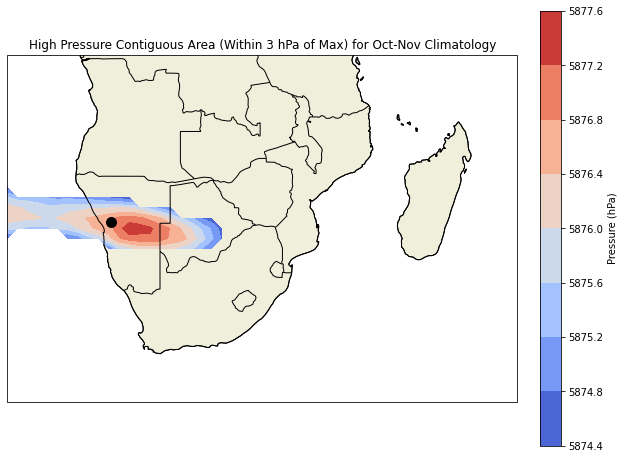

In [26]:
ds_oct_nov = NCEP_centroid.sel(time=NCEP_centroid['time'].dt.month.isin([1,2,12]))

# Compute climatology for October-November (average over years)
climatology_oct_nov = ds_oct_nov.groupby('time.year').mean(dim='time').mean(dim='year')

# Extract necessary data
#pressure_climatology = climatology_oct_nov['ERA5']  # Assuming 'pressure' is the variable
latitude = NCEP_centroid['lat']
longitude = NCEP_centroid['lon']

# Maximum pressure in the climatology
max_pressure_climatology = climatology_oct_nov.max(dim=['lat', 'lon'])

# Define the contiguous area within 3 hPa of the maximum pressure
threshold = 3  # 3 hPa threshold
contiguous_area = climatology_oct_nov.where(climatology_oct_nov >= (max_pressure_climatology - threshold))
contiguous_area=np.squeeze(contiguous_area)

# Compute the weighted centroid
# Convert lat/lon to radians and calculate the cosine weighting
latitude_radians = np.deg2rad(latitude)
weights_latitude = np.cos(latitude_radians)

# Apply latitude and longitude weights
weighted_latitude = (contiguous_area * weights_latitude * latitude).sum(dim=['lat', 'lon']) / \
                    (contiguous_area * weights_latitude).sum(dim=['lat', 'lon'])

weighted_longitude = (contiguous_area * longitude).sum(dim=['lat', 'lon']) / \
                     contiguous_area.sum(dim=['lat', 'lon'])

# Convert weighted latitude and longitude to values
centroid_lat = weighted_latitude.values
centroid_lon = weighted_longitude.values

# ---- Plotting the data ----

# Create a plot using Cartopy for a spatial map
fig = plt.figure(figsize=(10, 8))
ax = plt.axes(projection=ccrs.PlateCarree())

# Plot the pressure climatology and contiguous high-pressure area
contour = ax.contourf(longitude, latitude, contiguous_area, cmap='coolwarm', transform=ccrs.PlateCarree())

# Add coastlines and features
ax.coastlines()
ax.add_feature(cfeature.BORDERS)
ax.add_feature(cfeature.LAND, edgecolor='black')

# Add colorbar for pressure values
cbar = plt.colorbar(contour, ax=ax, orientation='vertical', fraction=0.046, pad=0.04)
cbar.set_label('Pressure (hPa)')

# Plot the centroid position
ax.plot(centroid_lon, centroid_lat, marker='o', color='black', markersize=10, transform=ccrs.PlateCarree())
#plt.text(centroid_lon + 1, centroid_lat, 'Centroid', fontsize=12, color='black', transform=ccrs.PlateCarree())

# Title and show plot
plt.title("High Pressure Contiguous Area (Within 3 hPa of Max) for Oct-Nov Climatology")
plt.show()

/tmp/ipykernel_133997/4261398745.py:115: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


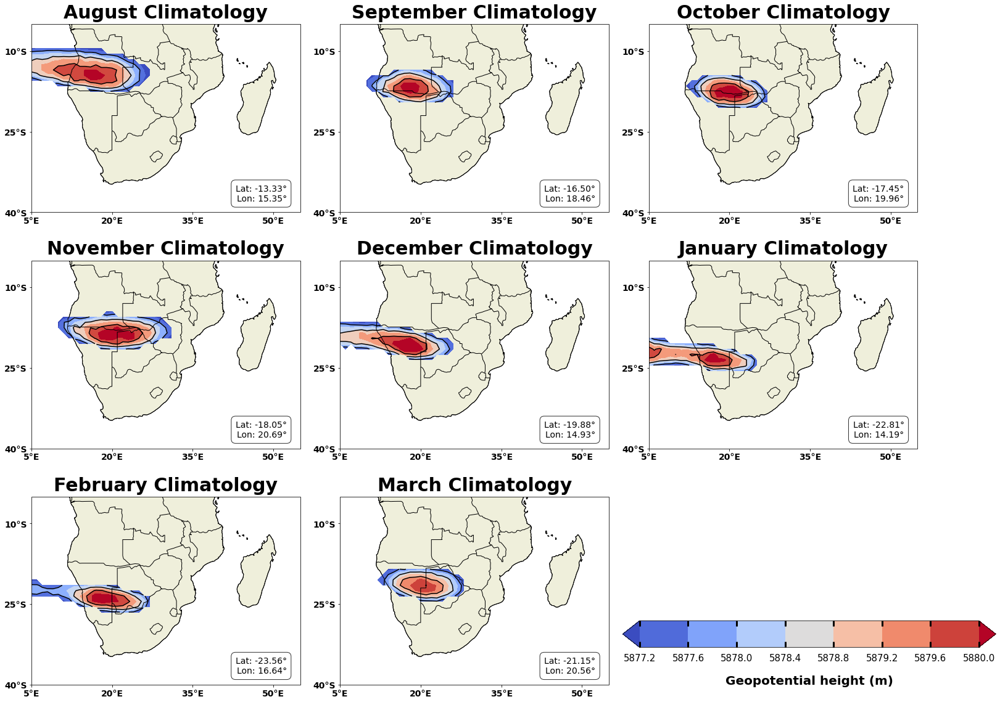

In [27]:
import matplotlib.font_manager as fm

# Define a bold font properties object
bold_font = fm.FontProperties(weight='bold', size=14)

months = [8, 9, 10, 11, 12, 1, 2, 3]

# Create a figure with subplots (3 rows, 3 columns)
fig, axes = plt.subplots(nrows=3, ncols=3, figsize=(21, 20), subplot_kw={'projection': ccrs.PlateCarree()})

# Flatten axes for easier iteration
axes = axes.flatten()

# Compute the overall mean geopotential height across all months
mean_pressure_all_months = NCEP_centroid.groupby('time.month').mean(dim='time').mean(dim='month')

# Flatten for colorbar
mean_pressure_flat = mean_pressure_all_months.values.flatten()
mean_pressure = mean_pressure_flat.mean()

# Loop over each month
for i, month in enumerate(months):
    ax = axes[i]
    
    # Filter the dataset for the specific month
    ds_month = NCEP_centroid.sel(time=NCEP_centroid['time'].dt.month == month)
    
    # Compute climatology for the selected month
    climatology_month = ds_month.groupby('time.year').mean(dim='time').mean(dim='year')

    # Extract latitude and longitude
    latitude = NCEP_centroid['lat']
    longitude = NCEP_centroid['lon']

    # Maximum pressure in the climatology
    max_pressure_climatology = climatology_month.max(dim=['lat', 'lon'])

    # Define the contiguous area within 3 hPa of the maximum pressure
    threshold = 3  # 3 hPa threshold
    contiguous_area = climatology_month.where(climatology_month >= (max_pressure_climatology - threshold))
    contiguous_area = np.squeeze(contiguous_area)
    
    # Convert lat/lon to radians and calculate the cosine weighting
    latitude_radians = np.deg2rad(latitude)
    weights_latitude = np.cos(latitude_radians)

    # Apply latitude and longitude weights to compute the centroid
    weighted_latitude = (contiguous_area * weights_latitude * latitude).sum(dim=['lat', 'lon']) / \
                        (contiguous_area * weights_latitude).sum(dim=['lat', 'lon'])

    weighted_longitude = (contiguous_area * longitude).sum(dim=['lat', 'lon']) / \
                         contiguous_area.sum(dim=['lat', 'lon'])

    # Convert weighted latitue and longitude to values
    centroid_lat = weighted_latitude.values
    centroid_lon = weighted_longitude.values
    # ---- Plotting the contiguous area ----

    # Plot only the contiguous high-pressure area with filled contours
    contour = ax.contourf(longitude, latitude, contiguous_area, cmap='coolwarm', transform=ccrs.PlateCarree(), extend='both', levels=8)
    
    # Add contour lines and label only 3 specific contour levels
    contours = ax.contour(longitude, latitude, contiguous_area, colors='black',levels=3, transform=ccrs.PlateCarree())
    #ax.clabel(contours, inline=True, fontsize=10, fmt='%1.1f',
              #levels=[contours.levels[1], contours.levels[len(contours.levels)//2], contours.levels[-2]])

    # Add coastlines and features
    ax.coastlines()
    ax.add_feature(cfeature.BORDERS)
    ax.add_feature(cfeature.LAND, edgecolor='black')

    # Plot the centroid position
    #ax.plot(centroid_lon, centroid_lat, marker='o', color='black', markersize=12, transform=ccrs.PlateCarree())

    # Set title for each month
    month_names = ['August', 'September', 'October', 'November', 'December', 'January', 'February', 'March']
    ax.set_title(f'{month_names[i]} Climatology', fontsize=30, fontweight='bold', pad=10)
    
    ax.set_extent((5, 55, -5, -40), crs=ccrs.PlateCarree())
    
    # Set latitude and longitude ticks
    ax.set_yticks(np.arange(-40, -5, 15), crs=ccrs.PlateCarree())
    lat_formatter = mticker.LatitudeFormatter()
    ax.yaxis.set_major_formatter(lat_formatter)
    #ax.tick_params(axis='y', labelsize=18)
    for label in ax.get_yticklabels():
        label.set_fontproperties(bold_font)
    
    ax.set_xticks(np.arange(5, 55, 15), crs=ccrs.PlateCarree())
    lon_formatter = mticker.LongitudeFormatter()
    ax.xaxis.set_major_formatter(lon_formatter)
    #ax.tick_params(axis='x', labelsize=18,labelweight='bold') 
    for label in ax.get_xticklabels():
        label.set_fontproperties(bold_font)
        
    # Add centroid latitude and longitude text
    ax.text(0.95, 0.05, f'Lat: {centroid_lat:.2f}°\nLon: {centroid_lon:.2f}°', 
            horizontalalignment='right', verticalalignment='bottom', 
            transform=ax.transAxes, fontsize=14, color='black', 
            bbox=dict(facecolor='white', alpha=0.8, boxstyle='round,pad=0.5'))

# Hide the last unused subplot
axes[-1].axis('off')

# Adjust layout and add colorbar
fig.subplots_adjust(hspace=-0.1,wspace=6)
cbar_ax = fig.add_axes([0.67, 0.17, 0.4, 0.03])  # Colorbar position

# Set the colorbar to reflect the mean geopotential height
cbar = fig.colorbar(contour, cax=cbar_ax, orientation='horizontal', fraction=0.02, pad=0.8)
cbar.ax.tick_params(axis='x', direction='in', length=9, width=3, colors='k', top=True, labelsize=15, pad=10)
cbar.set_label('Geopotential height (m)', fontsize=20, fontweight='bold', labelpad=20)
#fig.subplots_adjust(top=0.1,left=0.80,bottom=0.05,hspace=5,wspace=0.20)

plt.tight_layout()
fig.set_facecolor('w')

#plt.show()
# Save the figure
#plt.savefig('ERA5_Mon.png', dpi=300, bbox_inches='tight')



/tmp/ipykernel_133997/1436795260.py:108: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


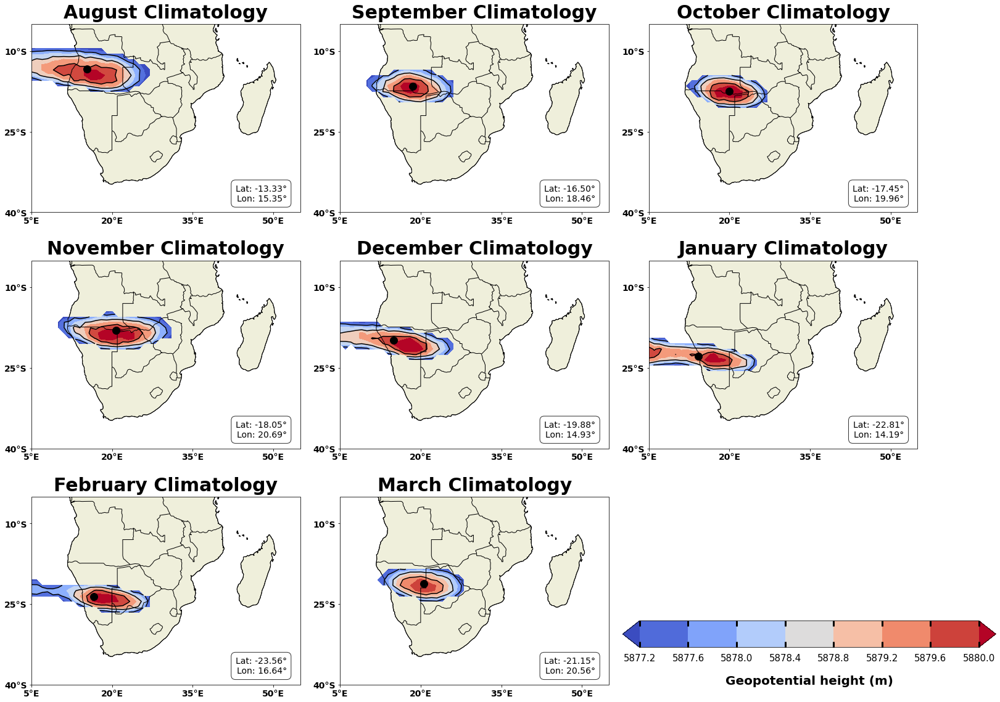

In [28]:

# Define a bold font properties object
bold_font = fm.FontProperties(weight='bold', size=14)

months = [8, 9, 10, 11, 12, 1, 2, 3]
month_names = ['August', 'September', 'October', 'November', 'December', 'January', 'February', 'March']

# Create a figure with subplots (3 rows, 3 columns)
fig, axes = plt.subplots(nrows=3, ncols=3, figsize=(21, 20), subplot_kw={'projection': ccrs.PlateCarree()})

# Flatten axes for easier iteration
axes = axes.flatten()

# Compute the overall mean geopotential height across all months
mean_pressure_all_months = NCEP_centroid.groupby('time.month').mean(dim='time').mean(dim='month')

# Flatten for colorbar
mean_pressure_flat = mean_pressure_all_months.values.flatten()
mean_pressure = mean_pressure_flat.mean()

# Loop over each month
for i, month in enumerate(months):
    ax = axes[i]
    
    # Filter the dataset for the specific month
    ds_month = NCEP_centroid.sel(time=NCEP_centroid['time'].dt.month == month)
    
    # Compute climatology for the selected month
    climatology_month = ds_month.groupby('time.year').mean(dim='time').mean(dim='year')

    # Extract latitude and longitude
    latitude = NCEP_centroid['lat']
    longitude = NCEP_centroid['lon']

    # Maximum pressure in the climatology
    max_pressure_climatology = climatology_month.max(dim=['lat', 'lon'])

    # Define the contiguous area within 3 hPa of the maximum pressure
    threshold = 3  # 3 hPa threshold
    contiguous_area = climatology_month.where(climatology_month >= (max_pressure_climatology - threshold))
    contiguous_area = np.squeeze(contiguous_area)
    
    # Convert lat/lon to radians and calculate the cosine weighting
    latitude_radians = np.deg2rad(latitude)
    weights_latitude = np.cos(latitude_radians)

    # Apply latitude and longitude weights to compute the centroid
    weighted_latitude = (contiguous_area * weights_latitude * latitude).sum(dim=['lat', 'lon']) / \
                        (contiguous_area * weights_latitude).sum(dim=['lat', 'lon'])

    weighted_longitude = (contiguous_area * longitude).sum(dim=['lat', 'lon']) / \
                         contiguous_area.sum(dim=['lat', 'lon'])

    # Convert weighted latitue and longitude to values
    centroid_lat = weighted_latitude.values
    centroid_lon = weighted_longitude.values

    # ---- Plotting the contiguous area ----
    # Plot only the contiguous high-pressure area with filled contours
    contour = ax.contourf(longitude, latitude, contiguous_area, cmap='coolwarm', transform=ccrs.PlateCarree(), extend='both', levels=8)
    
    # Add contour lines and label only 3 specific contour levels
    contours = ax.contour(longitude, latitude, contiguous_area, colors='black',levels=3, transform=ccrs.PlateCarree())

    # Add coastlines and features
    ax.coastlines()
    ax.add_feature(cfeature.BORDERS)
    ax.add_feature(cfeature.LAND, edgecolor='black')

    # Plot the centroid position as a marker
    ax.plot(centroid_lon, centroid_lat, marker='o', color='black', markersize=12, transform=ccrs.PlateCarree())

    # Set title for each month
    ax.set_title(f'{month_names[i]} Climatology', fontsize=30, fontweight='bold', pad=10)
    
    ax.set_extent((5, 55, -5, -40), crs=ccrs.PlateCarree())
    
    # Set latitude and longitude ticks
    ax.set_yticks(np.arange(-40, -5, 15), crs=ccrs.PlateCarree())
    lat_formatter = mticker.LatitudeFormatter()
    ax.yaxis.set_major_formatter(lat_formatter)
    for label in ax.get_yticklabels():
        label.set_fontproperties(bold_font)
    
    ax.set_xticks(np.arange(5, 55, 15), crs=ccrs.PlateCarree())
    lon_formatter = mticker.LongitudeFormatter()
    ax.xaxis.set_major_formatter(lon_formatter)
    for label in ax.get_xticklabels():
        label.set_fontproperties(bold_font)
        
    # Add centroid latitude and longitude text
    ax.text(0.95, 0.05, f'Lat: {centroid_lat:.2f}°\nLon: {centroid_lon:.2f}°', 
            horizontalalignment='right', verticalalignment='bottom', 
            transform=ax.transAxes, fontsize=14, color='black', 
            bbox=dict(facecolor='white', alpha=0.8, boxstyle='round,pad=0.5'))

# Hide the last unused subplot
axes[-1].axis('off')

# Adjust layout and add colorbar
fig.subplots_adjust(hspace=-0.1, wspace=6)
cbar_ax = fig.add_axes([0.67, 0.17, 0.4, 0.03])  # Colorbar position

# Set the colorbar to reflect the mean geopotential height
cbar = fig.colorbar(contour, cax=cbar_ax, orientation='horizontal', fraction=0.02, pad=0.8)
cbar.ax.tick_params(axis='x', direction='in', length=9, width=3, colors='k', top=True, labelsize=15, pad=10)
cbar.set_label('Geopotential height (m)', fontsize=20, fontweight='bold', labelpad=20)

plt.tight_layout()
fig.set_facecolor('w')
plt.show()


/tmp/ipykernel_133997/829232767.py:89: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


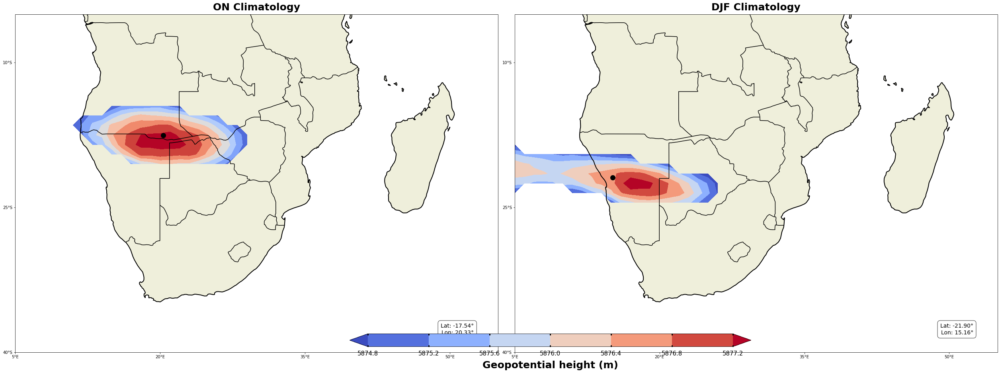

In [30]:

# Define the periods: Oct-Nov, Dec-Feb, and Mar-Apr
periods = {
    'ON': [10, 11],
    'DJF': [12, 1, 2]
}

# Create a figure with subplots (1 row, 3 columns for 3 periods)
fig, axes = plt.subplots(nrows=1, ncols=2, figsize=(35, 15), subplot_kw={'projection': ccrs.PlateCarree()})

# Loop over each period
for i, (period_name, period_months) in enumerate(periods.items()):
    ax = axes[i]

    # Filter the dataset for the specific months of the period
    ds_period = NCEP_centroid.sel(time=NCEP_centroid['time'].dt.month.isin(period_months))

    # Compute climatology for the selected period
    climatology_period = ds_period.groupby('time.year').mean(dim='time').mean(dim='year')

    # Extract latitude and longitude
    latitude = NCEP_centroid['lat']
    longitude = NCEP_centroid['lon']

    # Maximum pressure in the climatology
    max_pressure_climatology = climatology_period.max(dim=['lat', 'lon'])

    # Define the contiguous area within 3 hPa of the maximum pressure
    threshold = 3  # 3 hPa threshold
    contiguous_area = climatology_period.where(climatology_period >= (max_pressure_climatology - threshold))
    contiguous_area = np.squeeze(contiguous_area)

    # Convert lat/lon to radians and calculate the cosine weighting
    latitude_radians = np.deg2rad(latitude)
    weights_latitude = np.cos(latitude_radians)

    # Apply latitude and longitude weights to compute the centroid
    weighted_latitude = (contiguous_area * weights_latitude * latitude).sum(dim=['lat', 'lon']) / \
                        (contiguous_area * weights_latitude).sum(dim=['lat', 'lon'])

    weighted_longitude = (contiguous_area * longitude).sum(dim=['lat', 'lon']) / \
                         contiguous_area.sum(dim=['lat', 'lon'])

    # Convert weighted latitude and longitude to values
    centroid_lat = weighted_latitude.values
    centroid_lon = weighted_longitude.values

    # ---- Plotting the data for each period ----

    # Plot the contiguous high-pressure area
    contour = ax.contourf(longitude, latitude, contiguous_area, cmap='coolwarm', transform=ccrs.PlateCarree(), extend='both')

    # Add coastlines and features
    ax.coastlines(linewidth=2)
    ax.add_feature(cfeature.BORDERS,linewidth=1.5)
    ax.add_feature(cfeature.LAND, edgecolor='black')

    # Plot the centroid position
    ax.plot(centroid_lon, centroid_lat, marker='o', color='black', markersize=12, transform=ccrs.PlateCarree())
    #ax.text(centroid_lon + 1, centroid_lat, 'Centroid', fontsize=14, color='black', transform=ccrs.PlateCarree())

    # Set title for each period
    ax.set_title(f'{period_name} Climatology', fontsize=25, fontweight='bold', pad=10)

    ax.set_extent((5, 55, -5, -40), crs=ccrs.PlateCarree())

    #lat
    ax.set_yticks(np.arange(-40,-5,15), crs=ccrs.PlateCarree())
    lat_formatter = mticker.LatitudeFormatter()
    ax.yaxis.set_major_formatter(lat_formatter)
    
    #lon
    ax.set_xticks(np.arange(5,55,15), crs=ccrs.PlateCarree())
    lon_formatter = mticker.LongitudeFormatter()
    ax.xaxis.set_major_formatter(lon_formatter)

    # Display centroid coordinates in the bottom right corner of each subplot
    ax.text(0.95, 0.05, f'Lat: {centroid_lat:.2f}°\nLon: {centroid_lon:.2f}°', 
            horizontalalignment='right', verticalalignment='bottom', 
            transform=ax.transAxes, fontsize=14, color='black', 
            bbox=dict(facecolor='white', alpha=0.8, boxstyle='round,pad=0.5'))

# Adjust layout and add colorbar
fig.subplots_adjust(hspace=-0.1)
cbar_ax = fig.add_axes([0.35, 0.12, 0.4, 0.03])  # Colorbar position
cbar = fig.colorbar(contour, cax=cbar_ax, orientation='horizontal', fraction=0.02, pad=0.8)
cbar.ax.tick_params(axis='x', direction='in', length=4, width=3, colors='k', top=True, labelsize=15, pad=10)
cbar.set_label('Geopotential height (m)', fontsize=25, fontweight='bold', labelpad=10)

plt.tight_layout()
fig.set_facecolor('w')

#plt.savefig('Centroid_Clim_ERA5_ON_DJF.png',dpi=300,bbox_inches='tight')


In [12]:
#NCEP & ERA5

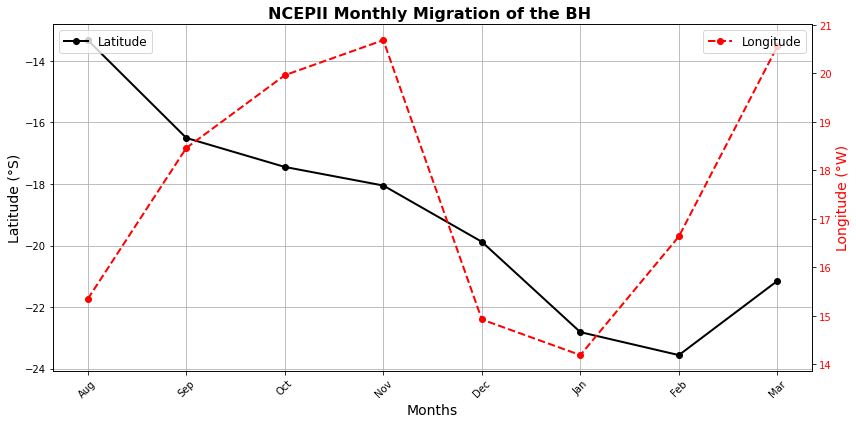

In [31]:
import numpy as np
import matplotlib.pyplot as plt

# Define the months from August to March
months = [8, 9, 10, 11, 12, 1, 2, 3]
month_names = ['Aug', 'Sep', 'Oct', 'Nov', 'Dec', 'Jan', 'Feb', 'Mar']

# Initialize lists to store the computed centroids (latitude and longitude)
centroid_latitudes = []
centroid_longitudes = []

# Loop over each month to compute centroids
for month in months:
    # Filter the dataset for the specific month
    ds_month = NCEP_centroid.sel(time=NCEP_centroid['time'].dt.month == month)
    
    # Compute climatology for the selected month
    climatology_month = ds_month.groupby('time.year').mean(dim='time').mean(dim='year')
    
    # Maximum pressure in the climatology
    max_pressure_climatology = climatology_month.max(dim=['lat', 'lon'])
    
    # Define the contiguous area within 3 hPa of the maximum pressure
    threshold = 3  # 3 hPa threshold
    contiguous_area = climatology_month.where(climatology_month >= (max_pressure_climatology - threshold))
    contiguous_area = np.squeeze(contiguous_area)
    
    # Extract latitude and longitude
    latitude = NCEP_centroid['lat']
    longitude = NCEP_centroid['lon']
    
    # Convert lat/lon to radians and calculate the cosine weighting
    latitude_radians = np.deg2rad(latitude)
    weights_latitude = np.cos(latitude_radians)

    # Apply latitude and longitude weights to compute the centroid
    weighted_latitude = (contiguous_area * weights_latitude * latitude).sum(dim=['lat', 'lon']) / \
                        (contiguous_area * weights_latitude).sum(dim=['lat', 'lon'])

    weighted_longitude = (contiguous_area * longitude).sum(dim=['lat', 'lon']) / \
                         contiguous_area.sum(dim=['lat', 'lon'])

    # Store the computed centroid values for each month
    centroid_latitudes.append(weighted_latitude.values)
    centroid_longitudes.append(weighted_longitude.values)

# ---- Plotting the Migration of the Botswana High (Lat & Lon) ----

fig, ax1 = plt.subplots(figsize=(12, 6))

# Plot latitude migration
ax1.plot(month_names, centroid_latitudes, marker='o', color='black', label='Latitude', linewidth=2)
ax1.set_xlabel('Months', fontsize=14)
ax1.set_ylabel('Latitude (°S)', fontsize=14, color='black')
ax1.tick_params(axis='y', labelcolor='black')
ax1.grid(True)
ax1.set_title('NCEPII Monthly Migration of the BH ', fontsize=16, fontweight='bold')
ax1.tick_params(axis='x', labelrotation=45)

# Create a second y-axis for longitude
ax2 = ax1.twinx()
ax2.plot(month_names, centroid_longitudes, marker='o',linestyle='--', color='r', label='Longitude', linewidth=2)
ax2.set_ylabel('Longitude (°W)', fontsize=14, color='r')
ax2.tick_params(axis='y', labelcolor='r')

# Legends
ax1.legend(loc='upper left', fontsize=12)
ax2.legend(loc='upper right', fontsize=12)

plt.tight_layout()
fig.set_facecolor('w')
#plt.savefig('Migration_NCEPII_ncep.png',dpi=300,bbox_inches='tight')

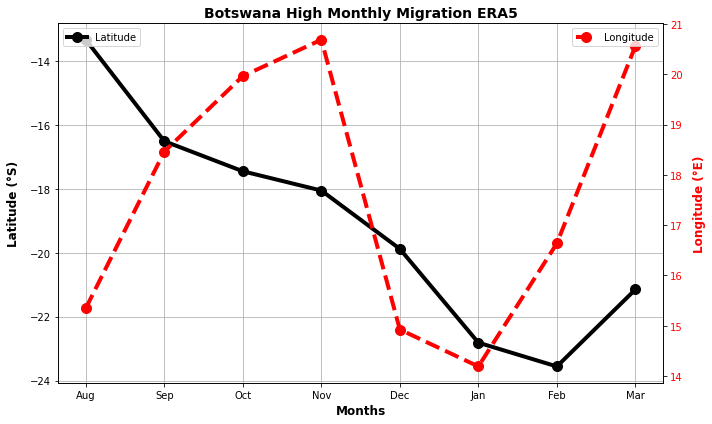

In [32]:
import numpy as np
import matplotlib.pyplot as plt

# Define the model ('ERA5')
models = ['ERA5']

# Initialize dictionaries to store results for the model
centroid_latitudes = {model: [] for model in models}
centroid_longitudes = {model: [] for model in models}

# Define the months from August to March
months = [8, 9, 10, 11, 12, 1, 2, 3]
month_names = ['Aug', 'Sep', 'Oct', 'Nov', 'Dec', 'Jan', 'Feb', 'Mar']

# Assuming data is available in a dictionary called 'centroid'
for model in models:
    ds = centroid[model]  # Load the dataset for the current model
    
    for month in months:
        # Select and process the data for each month
        ds_month = ds.sel(time=ds['time'].dt.month == month)
        climatology_month = ds_month.groupby('time.year').mean(dim='time').mean(dim='year')
        max_pressure_climatology = climatology_month.max(dim=['lat', 'lon'])
        
        # Define contiguous area within 3 hPa of the maximum pressure
        threshold = 3
        contiguous_area = climatology_month.where(climatology_month >= (max_pressure_climatology - threshold))
        contiguous_area = np.squeeze(contiguous_area)
        
        # Calculate the weighted centroids for latitude and longitude
        latitude = ds['lat']
        longitude = ds['lon']
        latitude_radians = np.deg2rad(latitude)
        weights_latitude = np.cos(latitude_radians)
        
        weighted_latitude = (contiguous_area * weights_latitude * latitude).sum(dim=['lat', 'lon']) / \
                            (contiguous_area * weights_latitude).sum(dim=['lat', 'lon'])
        weighted_longitude = (contiguous_area * longitude).sum(dim=['lat', 'lon']) / \
                             contiguous_area.sum(dim=['lat', 'lon'])
        
        # Append computed values to the lists
        centroid_latitudes[model].append(weighted_latitude.values)
        centroid_longitudes[model].append(weighted_longitude.values)

# ---- Plotting for a Single Model (ERA5) ----
fig, ax1 = plt.subplots(figsize=(10, 6))

# Plot latitude migration
ax1.plot(month_names, centroid_latitudes['ERA5'], marker='o',markersize=10, color='black', label='Latitude', linewidth=4)

# Plot longitude on a second y-axis
ax2 = ax1.twinx()
ax2.plot(month_names, centroid_longitudes['ERA5'], marker='o',markersize=10, linestyle='--', color='r', label='Longitude', linewidth=4)

# Set labels and titles
ax1.set_ylabel('Latitude (°S)', fontsize=12, color='black',fontweight='bold',labelpad=10)
ax2.set_ylabel('Longitude (°E)', fontsize=12, color='r',fontweight='bold',labelpad=10)
ax1.set_xlabel('Months', fontsize=12, fontweight='bold')
ax1.set_title(f'Botswana High Monthly Migration ERA5', fontsize=14, fontweight='bold')

# Legends
ax1.legend(loc='upper left')
ax2.legend(loc='upper right')

# Grid and x-axis label rotation
ax1.grid(True)
ax1.tick_params(axis='x')
ax2.tick_params(axis='y', labelcolor='r')

plt.tight_layout()
fig.set_facecolor('w')

# Show or save the plot
#plt.show()
#plt.savefig('Migration_ERA5_new.png', dpi=300, bbox_inches='tight')


/tmp/ipykernel_133997/2346571076.py:123: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


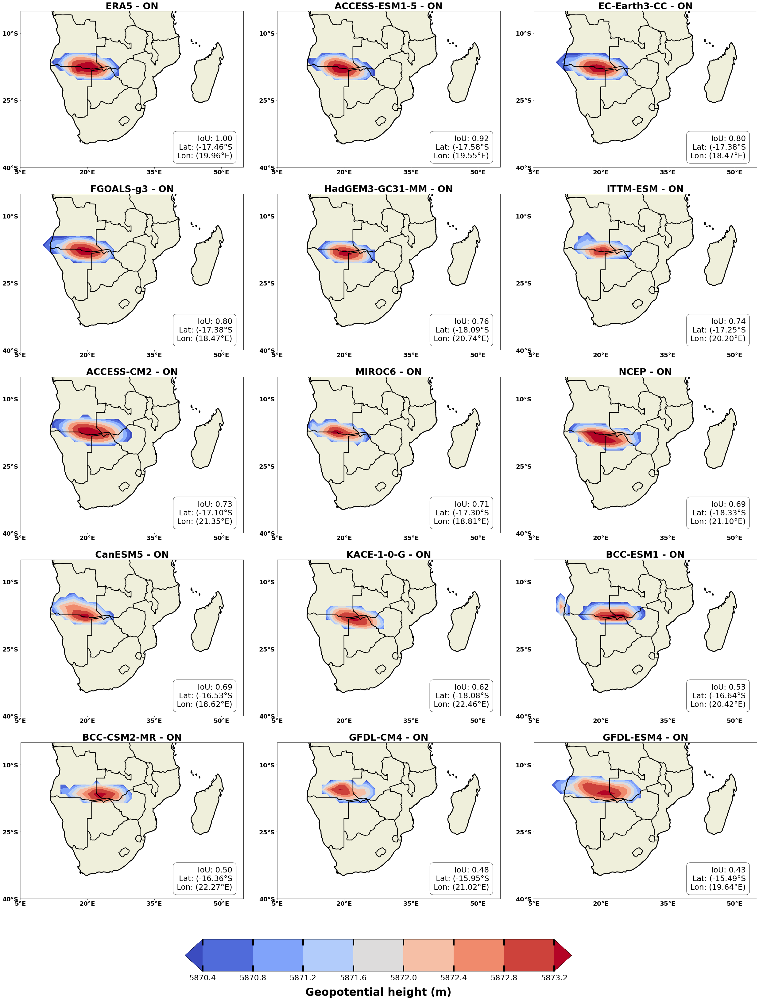

In [35]:
# Define the periods: Aug for now
periods = {
    'ON': [10]
}

# List of models to process
models = ['ERA5', 'NCEP', 'ACCESS-CM2', 'ACCESS-ESM1-5', 'BCC-ESM1',
          'BCC-CSM2-MR', 'CanESM5', 'EC-Earth3-CC', 'FGOALS-g3',
          'HadGEM3-GC31-MM', 'GFDL-ESM4', 'GFDL-CM4', 'ITTM-ESM', 'MIROC6', 'KACE-1-0-G']

n_periods = len(periods)

# Initialize list to store IoU values and corresponding model names
iou_list = []

# Compute ERA5 contiguous high-pressure area for IoU calculation
era5_ds = centroid['ERA5']
era5_period = era5_ds.sel(time=era5_ds['time'].dt.month.isin(periods['ON']))
era5_climatology = era5_period.groupby('time.year').mean(dim='time').mean(dim='year')
max_pressure_era5 = era5_climatology.max(dim=['lat', 'lon'])
era5_area = era5_climatology.where(era5_climatology >= (max_pressure_era5 - 3))  # 3 hPa threshold
era5_area = np.squeeze(era5_area)

# Calculate IoU for each model and store the values
for model in models:
    ds = centroid[model]
    for period_name, period_months in periods.items():
        ds_period = ds.sel(time=ds['time'].dt.month.isin(period_months))
        climatology_period = ds_period.groupby('time.year').mean(dim='time').mean(dim='year')
        
        # Compute high-pressure area for the model
        max_pressure_climatology = climatology_period.max(dim=['lat', 'lon'])
        contiguous_area = climatology_period.where(climatology_period >= (max_pressure_climatology - 3))
        contiguous_area = np.squeeze(contiguous_area)
        
        # IoU Calculation
        intersection = np.logical_and(contiguous_area.notnull(), era5_area.notnull()).sum().values
        union = np.logical_or(contiguous_area.notnull(), era5_area.notnull()).sum().values
        iou = intersection / union if union > 0 else 0  # Avoid division by zero
        
        # Store IoU and model name in the list
        iou_list.append((iou, model))

# Sort models based on IoU in descending order
iou_list.sort(reverse=True, key=lambda x: x[0])
sorted_models = [model for iou, model in iou_list]

# Set up the plot
n_cols = 3
n_rows = 7
fig, axes = plt.subplots(nrows=n_rows, ncols=n_cols, figsize=(35, 58), subplot_kw={'projection': ccrs.PlateCarree()})
axes = axes.flatten()

for i, model in enumerate(sorted_models):
    ds = centroid[model]
    for j, (period_name, period_months) in enumerate(periods.items()):
        ax = axes[i * n_periods + j]
        ds_period = ds.sel(time=ds['time'].dt.month.isin(period_months))
        climatology_period = ds_period.groupby('time.year').mean(dim='time').mean(dim='year')
        
        # Compute high-pressure area for the model
        max_pressure_climatology = climatology_period.max(dim=['lat', 'lon'])
        contiguous_area = climatology_period.where(climatology_period >= (max_pressure_climatology - 3))
        contiguous_area = np.squeeze(contiguous_area)
        
        # IoU Calculation (already calculated but we will reuse for plotting)
        iou = next(iou for iou, m in iou_list if m == model)
        
        # Compute centroid of the contiguous area using weighted latitude and longitude
        weighted_latitude = (contiguous_area * ds['lat']).sum(dim=['lat', 'lon']) / contiguous_area.sum()
        weighted_longitude = (contiguous_area * ds['lon']).sum(dim=['lat', 'lon']) / contiguous_area.sum()

        centroid_lat = weighted_latitude.values  # Assign latitude value
        centroid_lon = weighted_longitude.values  # Assign longitude value

        # Plot the contiguous area
        contour = ax.contourf(ds['lon'], ds['lat'], contiguous_area, cmap='coolwarm', transform=ccrs.PlateCarree(), extend='both')

        # Plot formatting
        ax.coastlines(linewidth=3)
        ax.add_feature(cfeature.BORDERS, linewidth=2.5)
        ax.add_feature(cfeature.LAND, edgecolor='black')

        # Plot centroid as a black marker
        #ax.plot(centroid_lon, centroid_lat, marker='o', color='black', markersize=15, transform=ccrs.PlateCarree())

        # Plot title with model and period name
        ax.set_title(f'{model} - {period_name}', fontsize=30, fontweight='bold', pad=5)
        ax.set_extent((5, 55, -5, -40), crs=ccrs.PlateCarree())

        # Display IoU value and centroid lat/lon in the bottom right corner
        ax.text(0.95, 0.05, f'IoU: {iou:.2f}\nLat: ({centroid_lat:.2f}°S\nLon: ({centroid_lon:.2f}°E)', 
                horizontalalignment='right', verticalalignment='bottom', 
                transform=ax.transAxes, fontsize=25, color='black', 
                bbox=dict(facecolor='white', alpha=0.8, boxstyle='round,pad=0.5'))

        # Latitude and Longitude labels formatting
        ax.set_yticks(np.arange(-40, -5, 15), crs=ccrs.PlateCarree())
        lat_formatter = mticker.LatitudeFormatter()
        ax.yaxis.set_major_formatter(lat_formatter)
        for label in ax.get_yticklabels():
            label.set_fontweight('bold')
            label.set_fontsize(20) 
                
        ax.set_xticks(np.arange(5, 55, 15), crs=ccrs.PlateCarree())
        lon_formatter = mticker.LongitudeFormatter()
        ax.xaxis.set_major_formatter(lon_formatter)
        for label in ax.get_xticklabels():
            label.set_fontweight('bold')
            label.set_fontsize(20) 

# Turn off the last two unused subplots
for k in range(n_rows * n_cols - 6, n_rows * n_cols):
    fig.delaxes(axes[k])

# Adjust layout and add colorbar
fig.subplots_adjust(wspace=8)
cbar_ax = fig.add_axes([0.25, 0.24, 0.5, 0.025])
cbar = fig.colorbar(contour, cax=cbar_ax, orientation='horizontal', fraction=0.02, pad=0.8)
cbar.ax.tick_params(axis='x', direction='in', length=20, width=5, colors='k', top=True, labelsize=25, pad=10)
cbar.set_label('Geopotential height (m)', fontsize=35, fontweight='bold', labelpad=18)

plt.tight_layout()
fig.set_facecolor('w')

#plt.savefig('ON_models_centroid.png',dpi=300,bbox_inches='tight')



/tmp/ipykernel_1619862/501869259.py:90: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


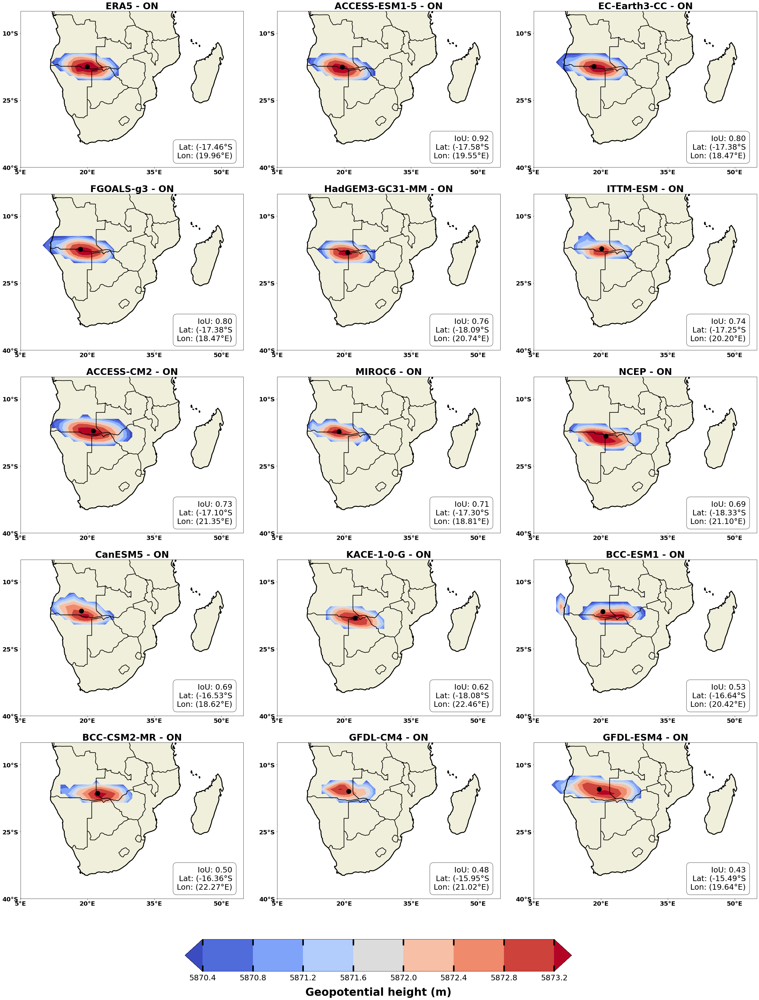

In [16]:
# Set up the plot
n_cols = 3
n_rows = 7
fig, axes = plt.subplots(nrows=n_rows, ncols=n_cols, figsize=(35, 58), subplot_kw={'projection': ccrs.PlateCarree()})
axes = axes.flatten()

# Fix ERA5 as the first model in the plot
fixed_model = 'ERA5'
remaining_models = [model for model in sorted_models if model != fixed_model]

# Loop through the models, starting with ERA5
for i, model in enumerate([fixed_model] + remaining_models):
    ds = centroid[model]
    for j, (period_name, period_months) in enumerate(periods.items()):
        ax = axes[i * n_periods + j]
        ds_period = ds.sel(time=ds['time'].dt.month.isin(period_months))
        climatology_period = ds_period.groupby('time.year').mean(dim='time').mean(dim='year')
        
        # Compute high-pressure area for the model
        max_pressure_climatology = climatology_period.max(dim=['lat', 'lon'])
        contiguous_area = climatology_period.where(climatology_period >= (max_pressure_climatology - 3))
        contiguous_area = np.squeeze(contiguous_area)
        
        # IoU Calculation (for models other than ERA5)
        if model != fixed_model:
            iou = next(iou for iou, m in iou_list if m == model)
        else:
            iou = None  # No IoU for ERA5

        # Compute centroid of the contiguous area using weighted latitude and longitude
        weighted_latitude = (contiguous_area * ds['lat']).sum(dim=['lat', 'lon']) / contiguous_area.sum()
        weighted_longitude = (contiguous_area * ds['lon']).sum(dim=['lat', 'lon']) / contiguous_area.sum()

        centroid_lat = weighted_latitude.values  # Assign latitude value
        centroid_lon = weighted_longitude.values  # Assign longitude value

        # Plot the contiguous area
        contour = ax.contourf(ds['lon'], ds['lat'], contiguous_area, cmap='coolwarm', transform=ccrs.PlateCarree(), extend='both')

        # Plot formatting
        ax.coastlines(linewidth=3)
        ax.add_feature(cfeature.BORDERS, linewidth=2)
        ax.add_feature(cfeature.LAND, edgecolor='black')

        # Plot centroid as a black marker
        ax.plot(centroid_lon, centroid_lat, marker='o', color='black', markersize=15, transform=ccrs.PlateCarree())

        # Plot title with model and period name
        ax.set_title(f'{model} - {period_name}', fontsize=30, fontweight='bold', pad=5)
        ax.set_extent((5, 55, -5, -40), crs=ccrs.PlateCarree())

        # Display IoU value for models (excluding ERA5) and centroid lat/lon
        if model != fixed_model:
            ax.text(0.95, 0.05, f'IoU: {iou:.2f}\nLat: ({centroid_lat:.2f}°S\nLon: ({centroid_lon:.2f}°E)', 
                    horizontalalignment='right', verticalalignment='bottom', 
                    transform=ax.transAxes, fontsize=25, color='black', 
                    bbox=dict(facecolor='white', alpha=0.8, boxstyle='round,pad=0.5'))
        else:
            ax.text(0.95, 0.05, f'Lat: ({centroid_lat:.2f}°S\nLon: ({centroid_lon:.2f}°E)', 
                    horizontalalignment='right', verticalalignment='bottom', 
                    transform=ax.transAxes, fontsize=25, color='black', 
                    bbox=dict(facecolor='white', alpha=0.8, boxstyle='round,pad=0.5'))

        # Latitude and Longitude labels formatting
        ax.set_yticks(np.arange(-40, -5, 15), crs=ccrs.PlateCarree())
        lat_formatter = mticker.LatitudeFormatter()
        ax.yaxis.set_major_formatter(lat_formatter)
        for label in ax.get_yticklabels():
            label.set_fontweight('bold')
            label.set_fontsize(20) 
                
        ax.set_xticks(np.arange(5, 55, 15), crs=ccrs.PlateCarree())
        lon_formatter = mticker.LongitudeFormatter()
        ax.xaxis.set_major_formatter(lon_formatter)
        for label in ax.get_xticklabels():
            label.set_fontweight('bold')
            label.set_fontsize(20)

# Turn off the last two unused subplots
for k in range(n_rows * n_cols - 6, n_rows * n_cols):
    fig.delaxes(axes[k])

# Adjust layout and add colorbar
fig.subplots_adjust(wspace=8)
cbar_ax = fig.add_axes([0.25, 0.24, 0.5, 0.025])
cbar = fig.colorbar(contour, cax=cbar_ax, orientation='horizontal', fraction=0.02, pad=0.8)
cbar.ax.tick_params(axis='x', direction='in', length=20, width=5, colors='k', top=True, labelsize=25, pad=10)
cbar.set_label('Geopotential height (m)', fontsize=35, fontweight='bold', labelpad=18)

plt.tight_layout()
fig.set_facecolor('w')

#plt.savefig('ERA5_CMIP6_iou_ON.png', dpi=300, bbox_inches='tight')  # Save plot if needed


/tmp/ipykernel_133997/2695288522.py:174: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


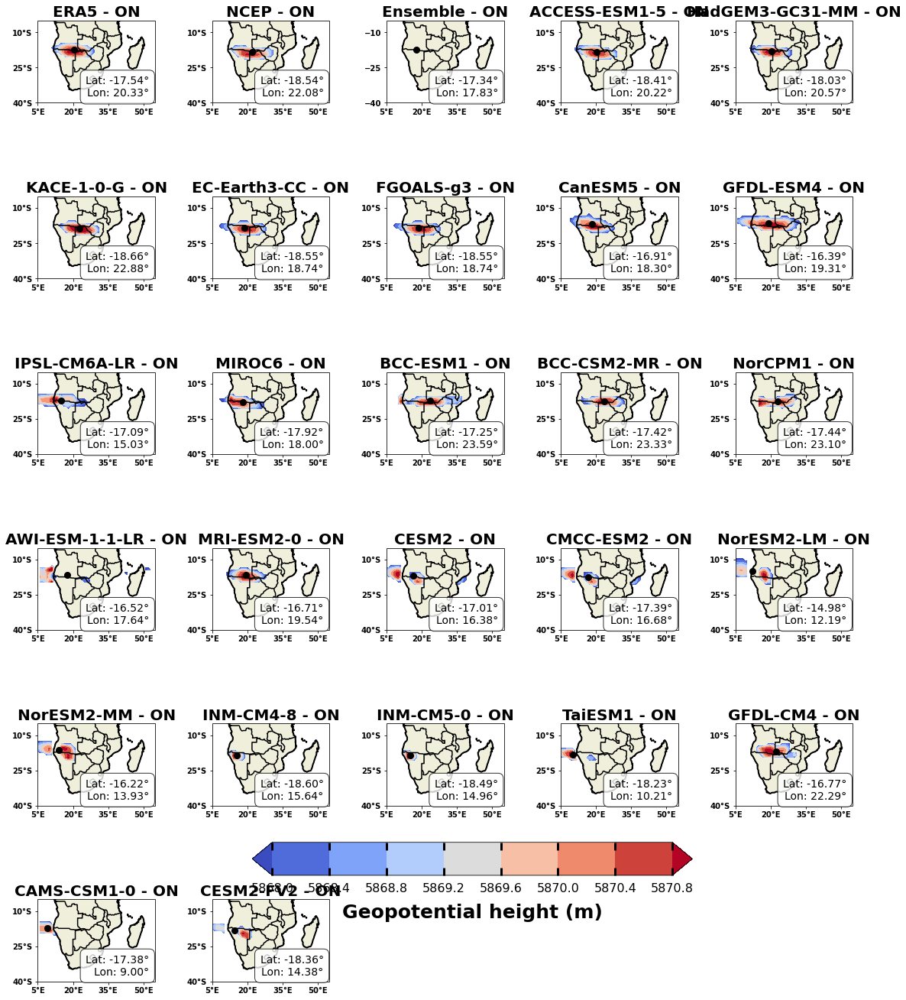

In [37]:
# Define the periods: August
periods = {
    'ON': [10,11]
}

# List of models to process (including ensemble models)
models = ['ERA5', 'NCEP', 'ACCESS-CM2', 'ACCESS-ESM1-5', 'HadGEM3-GC31-MM',
          'KACE-1-0-G', 'EC-Earth3-CC', 'FGOALS-g3', 'CanESM5', 'GFDL-ESM4',
          'IPSL-CM6A-LR', 'MIROC6','BCC-ESM1',
          'BCC-CSM2-MR','NorCPM1','AWI-ESM-1-1-LR','MRI-ESM2-0',
          'CESM2','CMCC-ESM2','NorESM2-LM','NorESM2-MM','INM-CM4-8',
          'INM-CM5-0','TaiESM1','GFDL-CM4','CAMS-CSM1-0','CESM2-FV2',
          'CMCC-CM2-SR5','MPI-ESM1-2-LR','NESM3']

# List of ensemble models only
Ens_models = ['ACCESS-CM2', 'ACCESS-ESM1-5', 'HadGEM3-GC31-MM', 
              'KACE-1-0-G', 'EC-Earth3-CC', 'FGOALS-g3', 'CanESM5', 
              'GFDL-ESM4', 'IPSL-CM6A-LR', 'MIROC6','BCC-ESM1',
          'BCC-CSM2-MR','NorCPM1','AWI-ESM-1-1-LR','MRI-ESM2-0',
          'CESM2','CMCC-ESM2','NorESM2-LM','NorESM2-MM','INM-CM4-8',
          'INM-CM5-0','TaiESM1','GFDL-CM4','CAMS-CSM1-0','CESM2-FV2',
          'CMCC-CM2-SR5','MPI-ESM1-2-LR','NESM3']

# Initialize variables to store sum for ensemble averaging
ensemble_lat_sum = 0
ensemble_lon_sum = 0
ensemble_contiguous_sum = None
ensemble_count = 0  # Counter to average over models

# Set up the plot
n_periods = len(periods)
n_models = len(models)
n_cols = 5
n_rows = 6
fig, axes = plt.subplots(nrows=n_rows, ncols=n_cols, figsize=(16, 20), subplot_kw={'projection': ccrs.PlateCarree()})

# Flatten axes array for easier indexing
axes = axes.flatten()

for i, model in enumerate(models):
    ds = centroid[model]  # Load the dataset for the current model
    for j, (period_name, period_months) in enumerate(periods.items()):
        # Skip the third subplot for individual models
        if i * n_periods + j == 2:
            continue

        ax = axes[i * n_periods + j]

        # Filter the dataset for the specific months of the period
        ds_period = ds.sel(time=ds['time'].dt.month.isin(period_months))

        # Compute climatology for the selected period
        climatology_period = ds_period.groupby('time.year').mean(dim='time').mean(dim='year')

        # Extract latitude and longitude
        latitude = ds['lat']
        longitude = ds['lon']

        # Maximum pressure in the climatology
        max_pressure_climatology = climatology_period.max(dim=['lat', 'lon'])

        # Define the contiguous area within 3 hPa of the maximum pressure
        threshold = 3  # 3 hPa threshold
        contiguous_area = climatology_period.where(climatology_period >= (max_pressure_climatology - threshold))
        contiguous_area = np.squeeze(contiguous_area)

        # Convert lat/lon to radians and calculate the cosine weighting
        latitude_radians = np.deg2rad(latitude)
        weights_latitude = np.cos(latitude_radians)

        # Apply latitude and longitude weights to compute the centroid
        weighted_latitude = (contiguous_area * weights_latitude * latitude).sum(dim=['lat', 'lon']) / \
                            (contiguous_area * weights_latitude).sum(dim=['lat', 'lon'])

        weighted_longitude = (contiguous_area * longitude).sum(dim=['lat', 'lon']) / \
                             contiguous_area.sum(dim=['lat', 'lon'])

        # Convert weighted latitude and longitude to values
        centroid_lat = weighted_latitude.values
        centroid_lon = weighted_longitude.values

        # Check if the model is part of the ensemble list
        if model in Ens_models:
            ensemble_lat_sum += centroid_lat
            ensemble_lon_sum += centroid_lon
            if ensemble_contiguous_sum is None:
                ensemble_contiguous_sum = contiguous_area
            else:
                ensemble_contiguous_sum += contiguous_area
            ensemble_count += 1

        # Plot the contiguous high-pressure area
        contour = ax.contourf(longitude, latitude, contiguous_area, cmap='coolwarm', transform=ccrs.PlateCarree(), extend='both')

        # Add coastlines and features
        ax.coastlines(linewidth=2)
        ax.add_feature(cfeature.BORDERS, linewidth=1.5)
        ax.add_feature(cfeature.LAND, edgecolor='black')

        # Plot the centroid position
        ax.plot(centroid_lon, centroid_lat, marker='o', color='black', markersize=8, transform=ccrs.PlateCarree())

        # Set title for each period and model
        ax.set_title(f'{model} - {period_name}', fontsize=20, fontweight='bold', pad=5)

        ax.set_extent((5, 55, -5, -40), crs=ccrs.PlateCarree())

        # Latitude ticks and formatting
        ax.set_yticks(np.arange(-40, -5, 15), crs=ccrs.PlateCarree())
        lat_formatter = mticker.LatitudeFormatter()
        ax.yaxis.set_major_formatter(lat_formatter)
        for label in ax.get_yticklabels():
            label.set_fontweight('bold')  # Make latitude labels bold

        # Longitude ticks and formatting
        ax.set_xticks(np.arange(5, 55, 15), crs=ccrs.PlateCarree())
        lon_formatter = mticker.LongitudeFormatter()
        ax.xaxis.set_major_formatter(lon_formatter)
        for label in ax.get_xticklabels():
            label.set_fontweight('bold')  # Make longitude labels bold

        # Display centroid coordinates in the bottom right corner of each subplot
        ax.text(0.95, 0.05, f'Lat: {centroid_lat:.2f}°\nLon: {centroid_lon:.2f}°', 
                horizontalalignment='right', verticalalignment='bottom', 
                transform=ax.transAxes, fontsize=14, color='black', 
                bbox=dict(facecolor='white', alpha=0.8, boxstyle='round,pad=0.5'))

# Compute ensemble mean centroid and contiguous area
ensemble_lat_mean = ensemble_lat_sum / ensemble_count
ensemble_lon_mean = ensemble_lon_sum / ensemble_count
ensemble_contiguous_mean = ensemble_contiguous_sum / ensemble_count

# Plot ensemble mean on the third subplot (axes[2])
ax_ensemble = axes[2]
ax_ensemble.contourf(longitude, latitude, ensemble_contiguous_mean, cmap='coolwarm', transform=ccrs.PlateCarree(), extend='both')
ax_ensemble.coastlines(linewidth=2)
ax_ensemble.add_feature(cfeature.BORDERS, linewidth=1.5)
ax_ensemble.add_feature(cfeature.LAND, edgecolor='black')
ax_ensemble.plot(ensemble_lon_mean, ensemble_lat_mean, marker='o', color='black', markersize=8, transform=ccrs.PlateCarree())
ax_ensemble.set_title(f'Ensemble - {period_name}', fontsize=20, fontweight='bold', pad=5)
ax_ensemble.set_extent((5, 55, -5, -40), crs=ccrs.PlateCarree())

# Latitude ticks and formatting
ax_ensemble.set_yticks(np.arange(-40, -5, 15), crs=ccrs.PlateCarree())
lat_formatter = mticker.LatitudeFormatter()
ax.yaxis.set_major_formatter(lat_formatter)
for label in ax_ensemble.get_yticklabels():
            label.set_fontweight('bold')  # Make latitude labels bold

        # Longitude ticks and formatting
ax_ensemble.set_xticks(np.arange(5, 55, 15), crs=ccrs.PlateCarree())
lon_formatter = mticker.LongitudeFormatter()
ax_ensemble.xaxis.set_major_formatter(lon_formatter)
for label in ax_ensemble.get_xticklabels():
            label.set_fontweight('bold') 

# Display ensemble mean centroid coordinates in the bottom right corner
ax_ensemble.text(0.95, 0.05, f'Lat: {ensemble_lat_mean:.2f}°\nLon: {ensemble_lon_mean:.2f}°', 
                 horizontalalignment='right', verticalalignment='bottom', 
                 transform=ax_ensemble.transAxes, fontsize=14, color='black', 
                 bbox=dict(facecolor='white', alpha=0.8, boxstyle='round,pad=0.5'))

# Turn off the last two unused subplots
for k in range(n_rows * n_cols - 3, n_rows * n_cols):
    fig.delaxes(axes[k])

# Adjust layout and add colorbar
fig.subplots_adjust(wspace=6)
cbar_ax = fig.add_axes([0.30, 0.16, 0.5, 0.03])  # Colorbar position
cbar = fig.colorbar(contour, cax=cbar_ax, orientation='horizontal', fraction=0.02, pad=0.8)
cbar.ax.tick_params(axis='x', direction='in', length=10, width=3, colors='k', top=True, labelsize=16, pad=10)
cbar.set_label('Geopotential height (m)', fontsize=25, fontweight='bold', labelpad=12)

plt.tight_layout()
fig.set_facecolor('w')

#plt.savefig('DJF_good_migration.png',dpi=300,bbox_inches='tight')


Processing model: ERA5
<xarray.DataArray 'ERA5' (time: 372, lat: 35, lon: 51)> Size: 3MB
[664020 values with dtype=float32]
Coordinates:
  * time     (time) datetime64[ns] 3kB 1984-01-16T12:00:00 ... 2014-12-16T12:...
  * lon      (lon) float64 408B 5.0 6.0 7.0 8.0 9.0 ... 51.0 52.0 53.0 54.0 55.0
  * lat      (lat) float64 280B -39.5 -38.5 -37.5 -36.5 ... -8.5 -7.5 -6.5 -5.5
Attributes:
    standard_name:  geopotential
    long_name:      Geopotential
    units:          m**2 s**-2
Dataset for ERA5 in period DJF:
<xarray.DataArray 'ERA5' (time: 93, lat: 35, lon: 51)> Size: 664kB
[166005 values with dtype=float32]
Coordinates:
  * time     (time) datetime64[ns] 744B 1984-01-16T12:00:00 ... 2014-12-16T12...
  * lon      (lon) float64 408B 5.0 6.0 7.0 8.0 9.0 ... 51.0 52.0 53.0 54.0 55.0
  * lat      (lat) float64 280B -39.5 -38.5 -37.5 -36.5 ... -8.5 -7.5 -6.5 -5.5
Attributes:
    standard_name:  geopotential
    long_name:      Geopotential
    units:          m**2 s**-2
Processing mod

Processing model: FGOALS-g3
<xarray.DataArray 'FGOALS-g3' (time: 372, plev_2: 1, lat: 35, lon: 51)> Size: 3MB
[664020 values with dtype=float32]
Coordinates:
  * time     (time) datetime64[ns] 3kB 1984-01-16T12:00:00 ... 2014-12-16T12:...
  * lon      (lon) float64 408B 5.0 6.0 7.0 8.0 9.0 ... 51.0 52.0 53.0 54.0 55.0
  * lat      (lat) float64 280B -39.5 -38.5 -37.5 -36.5 ... -8.5 -7.5 -6.5 -5.5
  * plev_2   (plev_2) float64 8B 5e+04
Attributes:
    standard_name:  geopotential_height
    long_name:      Geopotential Height
    units:          m
    comment:        Geopotential is the sum of the specific gravitational pot...
    cell_methods:   time: mean
    cell_measures:  area: areacella
    history:        2020-11-27T23:43:37Z altered by CMOR: Reordered dimension...
Dataset for FGOALS-g3 in period DJF:
<xarray.DataArray 'FGOALS-g3' (time: 93, plev_2: 1, lat: 35, lon: 51)> Size: 664kB
[166005 values with dtype=float32]
Coordinates:
  * time     (time) datetime64[ns] 744B 1984-01-16

/tmp/ipykernel_133997/667563344.py:175: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


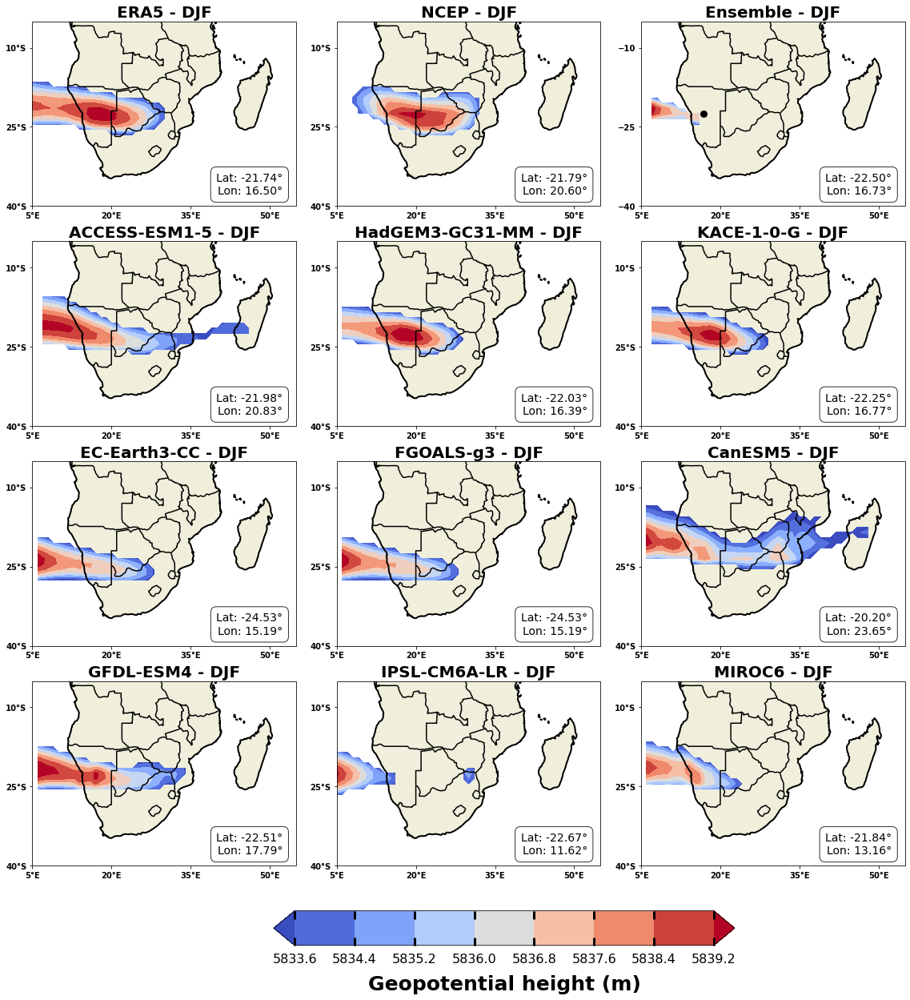

In [38]:
# Define the periods: August
periods = {
    'DJF': [1, 2, 12]
}

# List of models to process (including ensemble models)
models = ['ERA5', 'NCEP', 'ACCESS-CM2', 'ACCESS-ESM1-5', 'HadGEM3-GC31-MM',
          'KACE-1-0-G', 'EC-Earth3-CC', 'FGOALS-g3', 'CanESM5', 'GFDL-ESM4',
          'IPSL-CM6A-LR', 'MIROC6']

# List of ensemble models only
Ens_models = ['ACCESS-CM2', 'ACCESS-ESM1-5', 'HadGEM3-GC31-MM', 
              'KACE-1-0-G', 'EC-Earth3-CC', 'FGOALS-g3', 'CanESM5', 
              'GFDL-ESM4', 'IPSL-CM6A-LR', 'MIROC6']

# Initialize variables to store sum for ensemble averaging
ensemble_lat_sum = 0
ensemble_lon_sum = 0
ensemble_contiguous_sum = None
ensemble_count = 0  # Counter to average over models

# Set up the plot
n_periods = len(periods)
n_models = len(models)
n_cols = 3
n_rows = 5
fig, axes = plt.subplots(nrows=n_rows, ncols=n_cols, figsize=(16, 20), subplot_kw={'projection': ccrs.PlateCarree()})

# Flatten axes array for easier indexing
axes = axes.flatten()

for i, model in enumerate(models):
    print(f"Processing model: {model}")  # Debugging statement
    try:
        ds = centroid[model]  # Load the dataset for the current model
        print(ds)  # Debugging: print the dataset to check it's loading correctly
    except KeyError:
        print(f"Dataset for {model} not found in 'centroid'. Skipping model.")
        continue

    for j, (period_name, period_months) in enumerate(periods.items()):
        # Skip the third subplot for individual models
        if i * n_periods + j == 2:
            continue

        ax = axes[i * n_periods + j]

        # Filter the dataset for the specific months of the period
        ds_period = ds.sel(time=ds['time'].dt.month.isin(period_months))
        print(f"Dataset for {model} in period {period_name}:")
        print(ds_period)  # Debugging: check the period selection

        # Compute climatology for the selected period
        climatology_period = ds_period.groupby('time.year').mean(dim='time').mean(dim='year')

        # Extract latitude and longitude
        latitude = ds['lat']
        longitude = ds['lon']

        # Maximum pressure in the climatology
        max_pressure_climatology = climatology_period.max(dim=['lat', 'lon'])

        # Define the contiguous area within 3 hPa of the maximum pressure
        threshold = 6  # 3 hPa threshold
        contiguous_area = climatology_period.where(climatology_period >= (max_pressure_climatology - threshold))
        contiguous_area = np.squeeze(contiguous_area)

        # Convert lat/lon to radians and calculate the cosine weighting
        latitude_radians = np.deg2rad(latitude)
        weights_latitude = np.cos(latitude_radians)

        # Apply latitude and longitude weights to compute the centroid
        weighted_latitude = (contiguous_area * weights_latitude * latitude).sum(dim=['lat', 'lon']) / \
                            (contiguous_area * weights_latitude).sum(dim=['lat', 'lon'])

        weighted_longitude = (contiguous_area * longitude).sum(dim=['lat', 'lon']) / \
                             contiguous_area.sum(dim=['lat', 'lon'])

        # Convert weighted latitude and longitude to values
        centroid_lat = weighted_latitude.values
        centroid_lon = weighted_longitude.values

        # Check if the model is part of the ensemble list
        if model in Ens_models:
            ensemble_lat_sum += centroid_lat
            ensemble_lon_sum += centroid_lon
            if ensemble_contiguous_sum is None:
                ensemble_contiguous_sum = contiguous_area
            else:
                ensemble_contiguous_sum += contiguous_area
            ensemble_count += 1

        # Plot the contiguous high-pressure area
        contour = ax.contourf(longitude, latitude, contiguous_area, cmap='coolwarm', transform=ccrs.PlateCarree(), extend='both')

        # Add coastlines and features
        ax.coastlines(linewidth=2)
        ax.add_feature(cfeature.BORDERS, linewidth=1.5)
        ax.add_feature(cfeature.LAND, edgecolor='black')

        # Plot the centroid position
        #ax.plot(centroid_lon, centroid_lat, marker='o', color='black', markersize=8, transform=ccrs.PlateCarree())

        # Set title for each period and model
        ax.set_title(f'{model} - {period_name}', fontsize=20, fontweight='bold', pad=5)

        ax.set_extent((5, 55, -5, -40), crs=ccrs.PlateCarree())

        # Latitude ticks and formatting
        ax.set_yticks(np.arange(-40, -5, 15), crs=ccrs.PlateCarree())
        lat_formatter = mticker.LatitudeFormatter()
        ax.yaxis.set_major_formatter(lat_formatter)
        for label in ax.get_yticklabels():
            label.set_fontweight('bold')  # Make latitude labels bold

        # Longitude ticks and formatting
        ax.set_xticks(np.arange(5, 55, 15), crs=ccrs.PlateCarree())
        lon_formatter = mticker.LongitudeFormatter()
        ax.xaxis.set_major_formatter(lon_formatter)
        for label in ax.get_xticklabels():
            label.set_fontweight('bold')  # Make longitude labels bold

        # Display centroid coordinates in the bottom right corner of each subplot
        ax.text(0.95, 0.05, f'Lat: {centroid_lat:.2f}°\nLon: {centroid_lon:.2f}°', 
                horizontalalignment='right', verticalalignment='bottom', 
                transform=ax.transAxes, fontsize=14, color='black', 
                bbox=dict(facecolor='white', alpha=0.8, boxstyle='round,pad=0.5'))

# Compute ensemble mean centroid and contiguous area
ensemble_lat_mean = ensemble_lat_sum / ensemble_count
ensemble_lon_mean = ensemble_lon_sum / ensemble_count
ensemble_contiguous_mean = ensemble_contiguous_sum / ensemble_count

# Plot ensemble mean on the third subplot (axes[2])
ax_ensemble = axes[2]
ax_ensemble.contourf(longitude, latitude, ensemble_contiguous_mean, cmap='coolwarm', transform=ccrs.PlateCarree(), extend='both')
ax_ensemble.coastlines(linewidth=2)
ax_ensemble.add_feature(cfeature.BORDERS, linewidth=1.5)
ax_ensemble.add_feature(cfeature.LAND, edgecolor='black')
ax_ensemble.plot(ensemble_lon_mean, ensemble_lat_mean, marker='o', color='black', markersize=8, transform=ccrs.PlateCarree())
ax_ensemble.set_title(f'Ensemble - {period_name}', fontsize=20, fontweight='bold', pad=5)
ax_ensemble.set_extent((5, 55, -5, -40), crs=ccrs.PlateCarree())

# Latitude ticks and formatting
ax_ensemble.set_yticks(np.arange(-40, -5, 15), crs=ccrs.PlateCarree())
lat_formatter = mticker.LatitudeFormatter()
ax.yaxis.set_major_formatter(lat_formatter)
for label in ax_ensemble.get_yticklabels():
    label.set_fontweight('bold')  # Make latitude labels bold

# Longitude ticks and formatting
ax_ensemble.set_xticks(np.arange(5, 55, 15), crs=ccrs.PlateCarree())
lon_formatter = mticker.LongitudeFormatter()
ax_ensemble.xaxis.set_major_formatter(lon_formatter)
for label in ax_ensemble.get_xticklabels():
    label.set_fontweight('bold') 

# Display ensemble mean centroid coordinates in the bottom right corner
ax_ensemble.text(0.95, 0.05, f'Lat: {ensemble_lat_mean:.2f}°\nLon: {ensemble_lon_mean:.2f}°', 
                 horizontalalignment='right', verticalalignment='bottom', 
                 transform=ax_ensemble.transAxes, fontsize=14, color='black', 
                 bbox=dict(facecolor='white', alpha=0.8, boxstyle='round,pad=0.5'))

# Turn off the last two unused subplots
for k in range(n_rows * n_cols - 3, n_rows * n_cols):
    fig.delaxes(axes[k])

# Adjust layout and add colorbar
fig.subplots_adjust(wspace=6)
cbar_ax = fig.add_axes([0.30, 0.16, 0.5, 0.03])  # Colorbar position
cbar = fig.colorbar(contour, cax=cbar_ax, orientation='horizontal', fraction=0.02, pad=0.8)
cbar.ax.tick_params(axis='x', direction='in', length=10, width=3, colors='k', top=True, labelsize=16, pad=10)
cbar.set_label('Geopotential height (m)', fontsize=25, fontweight='bold', labelpad=12)

plt.tight_layout()
fig.set_facecolor('w')

#plt.savefig('DJF_centroid_models.png',dpi=300,bbox_inches='tight')

/tmp/ipykernel_1619862/49551819.py:104: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


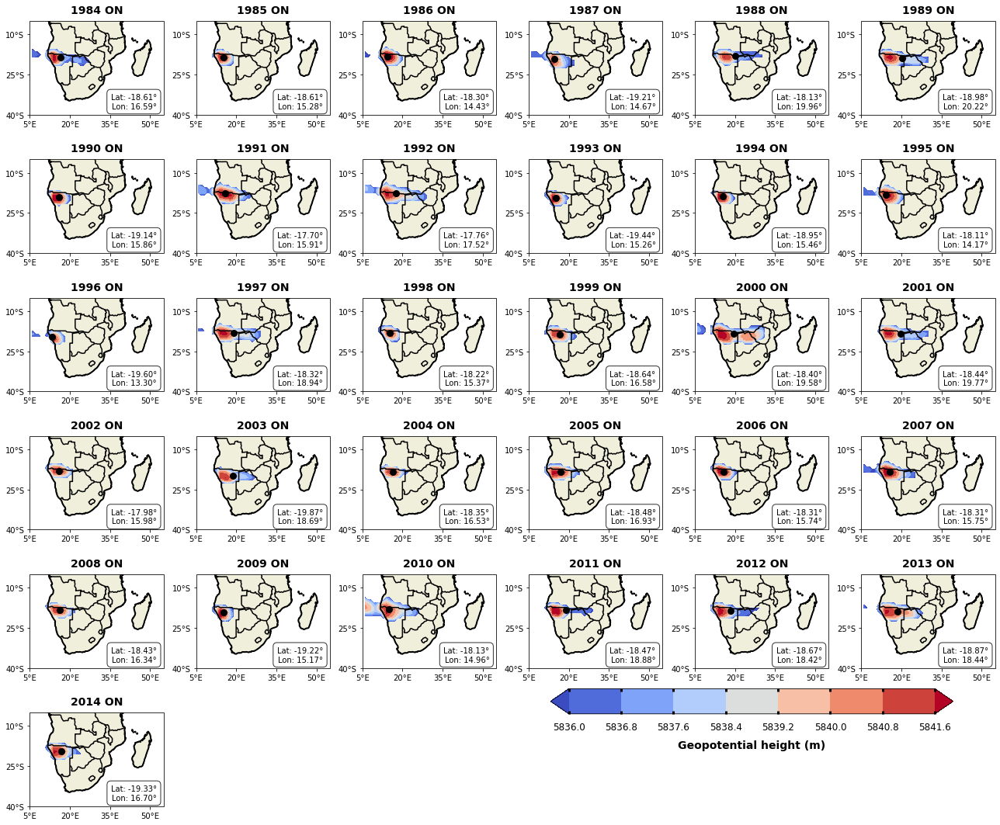

In [19]:
# Define the periods: Oct-Nov
periods = {
    'ON': [10,11]  # October-November
}

# List of models to process
models = ['INM-CM4-8']

# Set up the plot with 3 columns and 4 rows
n_cols = 6
n_rows = 6
fig, axes = plt.subplots(nrows=n_rows, ncols=n_cols, figsize=(18, 15), subplot_kw={'projection': ccrs.PlateCarree()})

# Flatten axes array for easier indexing
axes = axes.flatten()

# Generate years list from 1984 to 2014
years = np.arange(1984, 2015)

for i, model in enumerate(models):
    ds = centroid[model]  # Load the dataset for the current model
    for j, year in enumerate(years):
        for period_name, period_months in periods.items():
            ax = axes[j]  # Select the correct axis for this year
            
            # Filter the dataset for the specific year and months of the period
            ds_year = ds.sel(time=(ds['time.year'] == year) & ds['time'].dt.month.isin(period_months))
            
            # Compute the mean climatology for this year and period
            climatology_year = ds_year.mean(dim='time')
            
            # Extract latitude and longitude
            latitude = ds['lat']
            longitude = ds['lon']

            # Maximum pressure in the climatology
            max_pressure_climatology = climatology_year.max(dim=['lat', 'lon'])

            # Define the contiguous area within 3 hPa of the maximum pressure
            threshold = 6  # 3 hPa threshold
            contiguous_area = climatology_year.where(climatology_year >= (max_pressure_climatology - threshold))
            contiguous_area = np.squeeze(contiguous_area)

            # Convert lat/lon to radians and calculate the cosine weighting
            latitude_radians = np.deg2rad(latitude)
            weights_latitude = np.cos(latitude_radians)

            # Apply latitude and longitude weights to compute the centroid
            weighted_latitude = (contiguous_area * weights_latitude * latitude).sum(dim=['lat', 'lon']) / \
                                (contiguous_area * weights_latitude).sum(dim=['lat', 'lon'])

            weighted_longitude = (contiguous_area * longitude).sum(dim=['lat', 'lon']) / \
                                 contiguous_area.sum(dim=['lat', 'lon'])

            # Convert weighted latitude and longitude to values
            centroid_lat = weighted_latitude.values
            centroid_lon = weighted_longitude.values

            # Plot the contiguous high-pressure area
            contour = ax.contourf(longitude, latitude, contiguous_area, cmap='coolwarm', transform=ccrs.PlateCarree(), extend='both')

            # Add coastlines and features
            ax.coastlines(linewidth=2)
            ax.add_feature(cfeature.BORDERS, linewidth=1.5)
            ax.add_feature(cfeature.LAND, edgecolor='black')

            # Plot the centroid position
            ax.plot(centroid_lon, centroid_lat, marker='o', color='black', markersize=8, transform=ccrs.PlateCarree())
            ax.text(centroid_lon + 1, centroid_lat, 'Centroid', fontsize=0, color='black', transform=ccrs.PlateCarree())

            # Set title for each year
            ax.set_title(f'{year} {period_name}', fontsize=14, fontweight='bold', pad=10)

            ax.set_extent((5, 55, -5, -40), crs=ccrs.PlateCarree())

            # Latitude ticks and formatting
            ax.set_yticks(np.arange(-40, -5, 15), crs=ccrs.PlateCarree())
            lat_formatter = mticker.LatitudeFormatter()
            ax.yaxis.set_major_formatter(lat_formatter)

            # Longitude ticks and formatting
            ax.set_xticks(np.arange(5, 55, 15), crs=ccrs.PlateCarree())
            lon_formatter = mticker.LongitudeFormatter()
            ax.xaxis.set_major_formatter(lon_formatter)

            # Display centroid coordinates in the bottom right corner of each subplot
            ax.text(0.95, 0.05, f'Lat: {centroid_lat:.2f}°\nLon: {centroid_lon:.2f}°', 
                    horizontalalignment='right', verticalalignment='bottom', 
                    transform=ax.transAxes, fontsize=10, color='black', 
                    bbox=dict(facecolor='white', alpha=0.8, boxstyle='round,pad=0.5'))

# Turn off the last unused subplots if necessary
for k in range(len(years), n_rows * n_cols):
    if k < len(axes):  # Ensure the index is within the range of axes
        fig.delaxes(axes[k])

# Adjust layout and add colorbar
fig.subplots_adjust(hspace=0.3, wspace=0.2)
cbar_ax = fig.add_axes([0.55, 0.14, 0.4, 0.03])  # Colorbar position
cbar = fig.colorbar(contour, cax=cbar_ax, orientation='horizontal', fraction=0.02, pad=0.8)
cbar.ax.tick_params(axis='x', direction='in', length=4, width=3, colors='k', top=True, labelsize=12, pad=10)
cbar.set_label('Geopotential height (m)', fontsize=14, fontweight='bold', labelpad=10)

plt.tight_layout()
fig.set_facecolor('w')

#plt.savefig('Annual_ERA5_1984_2014_ON.png', dpi=300, bbox_inches='tight')


In [20]:
#Centroid interannual variability

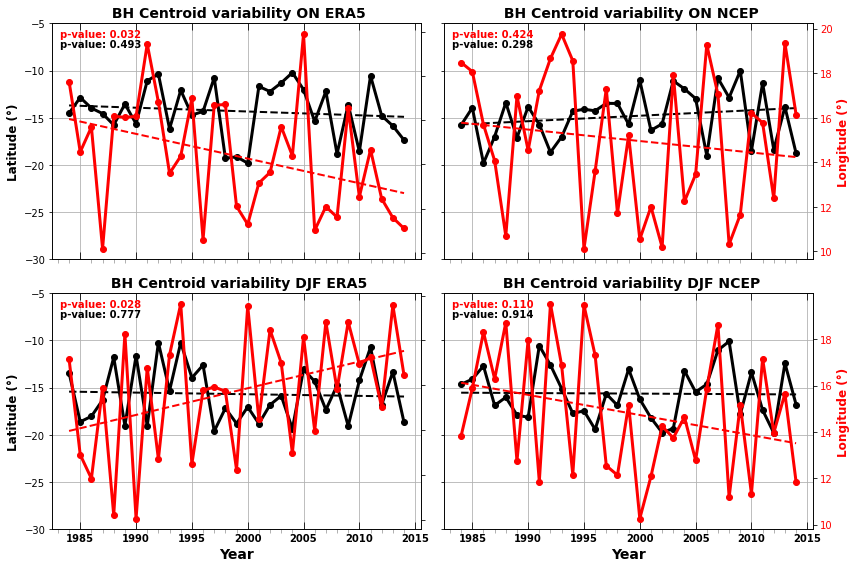

In [21]:
import matplotlib.pyplot as plt
import numpy as np
from scipy.stats import linregress

# Define the periods: Oct-Nov (ON) and Dec-Feb (DJF)
periods = {
    'ON': [10, 11],    # October-November
    'DJF': [12, 1, 2]  # December-January-February
}

# List of models to process
models = ['ERA5', 'NCEP']

# Generate years list from 1984 to 2015
years = np.arange(1984, 2015)

# Create dictionaries to store centroid latitude and longitude for each period and model
centroid_latitudes = {model: {period: [] for period in periods} for model in models}
centroid_longitudes = {model: {period: [] for period in periods} for model in models}

# Sample random data for testing purposes
np.random.seed(0)
for model in models:
    for period_name in periods:
        centroid_latitudes[model][period_name] = np.random.uniform(-20, -10, len(years))
        centroid_longitudes[model][period_name] = np.random.uniform(10, 20, len(years))

# Function to compute linear trend (slope) and p-value
def compute_trend(x, y):
    slope, intercept, r_value, p_value, std_err = linregress(x, y)
    return slope, intercept, p_value

# Create a 2x2 grid of subplots
fig, axs = plt.subplots(2, 2, figsize=(12, 8))

# Define line styles, colors, and markers for plotting
colors = {'latitude': 'black', 'longitude': 'r'}
markers = {'ON': 'o', 'DJF': 'o'}
line_styles = {'ON': '-', 'DJF': '-'}

# Plot the data for each combination (ON/DJF for ERA5 and NCEP)
plot_info = [
    ('ERA5', 'ON'), ('NCEP', 'ON'),  # First row: ON period for ERA5 and NCEP
    ('ERA5', 'DJF'), ('NCEP', 'DJF') # Second row: DJF period for ERA5 and NCEP
]

# Loop over plot_info to plot latitude on the left and longitude on the right of the same plot
for i, (model, period_name) in enumerate(plot_info):
    ax1 = axs[i // 2, i % 2]  # Select the appropriate subplot
    
    # Plot latitude on the left y-axis (black)
    ax1.plot(years, centroid_latitudes[model][period_name], 
             label=f'{model} {period_name} Latitude', 
             color=colors['latitude'], linestyle=line_styles[period_name], linewidth=3, marker=markers[period_name])
    
    # Compute and plot the latitude trend
    lat_slope, lat_intercept, lat_p_value = compute_trend(years, centroid_latitudes[model][period_name])
    ax1.plot(years, lat_slope * years + lat_intercept, 
             color=colors['latitude'], linestyle='--', linewidth=2, label=f'{model} {period_name} Lat Trend')
    
    # Annotate the p-value for the latitude trend
    ax1.text(0.02, 0.90, f'p-value: {lat_p_value:.3f}', transform=ax1.transAxes, fontsize=10, color='black', fontweight='bold')
    
    # Remove year labels for ERA5 ON and NCEP ON
    if model == 'ERA5' and period_name == 'ON':
        ax1.set_xticklabels([])  # Remove year labels for ERA5 ON
    elif model == 'NCEP' and period_name == 'ON':
        ax1.set_xticklabels([])  # Remove year labels for NCEP ON
    else:
        ax1.set_xlabel('Year', fontsize=14, fontweight='bold')
    
    # Set latitude limits from -30 to -5
    ax1.set_ylim(-30, -5)

    # Only set latitude label for ERA5 plots
    if model == 'ERA5':
        ax1.set_ylabel('Latitude (°)', color=colors['latitude'], fontsize=12, fontweight='bold')
    else:
        ax1.set_yticklabels([])  # Remove latitude labels for NCEP
    ax1.tick_params(axis='y', labelcolor=colors['latitude'])
    ax1.grid(True)
    
    # Create a second y-axis for longitude (red)
    ax2 = ax1.twinx()
    ax2.plot(years, centroid_longitudes[model][period_name], 
             label=f'{model} {period_name} Longitude', 
             color=colors['longitude'], linestyle=line_styles[period_name], linewidth=3, marker=markers[period_name])
    
    # Compute and plot the longitude trend
    lon_slope, lon_intercept, lon_p_value = compute_trend(years, centroid_longitudes[model][period_name])
    ax2.plot(years, lon_slope * years + lon_intercept, 
             color=colors['longitude'], linestyle='--', linewidth=2, label=f'{model} {period_name} Lon Trend')
    
    # Annotate the p-value for the longitude trend
    ax2.text(0.02, 0.94, f'p-value: {lon_p_value:.3f}', transform=ax2.transAxes, fontsize=10, color='red', fontweight='bold')
    
    # Only set longitude label for NCEP plots
    if model == 'NCEP':
        ax2.set_ylabel('Longitude (°)', color=colors['longitude'], fontsize=12, fontweight='bold')
    else:
        ax2.set_yticklabels([])  # Remove longitude labels for ERA5
    ax2.tick_params(axis='y', labelcolor=colors['longitude'])
    
    # Set titles
    ax1.set_title(f' BH Centroid variability {period_name} {model}', fontsize=14, fontweight='bold')

    # Configure top x-axis for minor ticks
    ax1.xaxis.set_minor_locator(plt.MultipleLocator(1))  # Add minor ticks every year
    ax1.tick_params(axis='x', which='minor', length=4, color='gray')  # Minor ticks appearance
    ax1.tick_params(axis='x', which='major', length=7)  # Major ticks appearance
    ax1.tick_params(axis='x', top=True, direction='in')  # Enable ticks at the top
    
    # Make year ticks bold
    for label in ax1.get_xticklabels():
        label.set_fontweight('bold')

# Adjust layout for better spacing
fig.tight_layout()
fig.set_facecolor('w')

# save
#plt.savefig('Annual_ERA5_NCEP_1984_2014_ON_DJF.png', dpi=300, bbox_inches='tight')



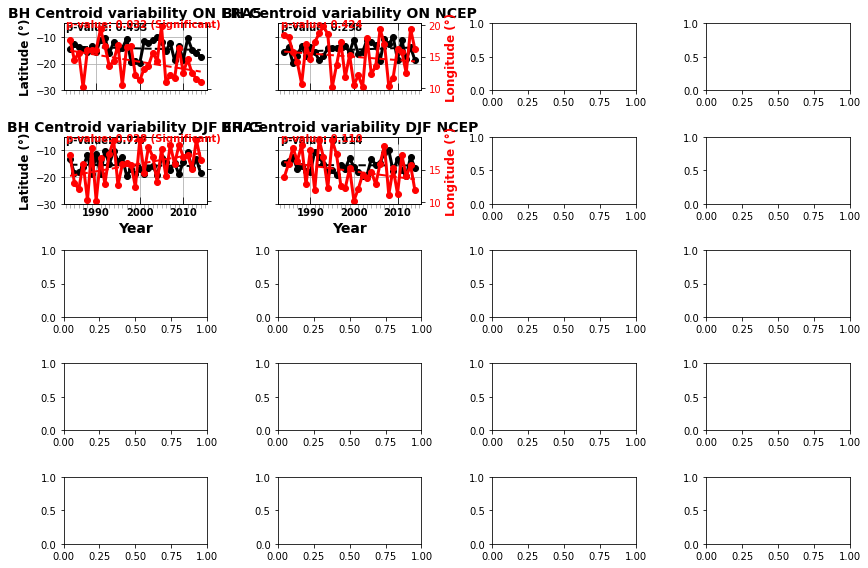

In [22]:
import matplotlib.pyplot as plt
import numpy as np
from scipy.stats import linregress

# Define the periods: Oct-Nov (ON) and Dec-Feb (DJF)
periods = {
    'ON': [10, 11],    # October-November
    'DJF': [12, 1, 2]  # December-January-February
}

# List of models to process
#models = ['ERA5', 'NCEP']

models1 = ['NCEP','ERA5','ACCESS-CM2', 'ACCESS-ESM1-5', 'HadGEM3-GC31-MM',
                   'KACE-1-0-G', 'EC-Earth3-CC', 'FGOALS-g3','CanESM5', 
                   'GFDL-ESM4','GFDL-CM4','BCC-ESM1','BCC-CSM2-MR',
          'NorCPM1','MRI-ESM2-0']
# Generate years list from 1984 to 2015
years = np.arange(1984, 2015)

# Create dictionaries to store centroid latitude and longitude for each period and model
centroid_latitudes = {model: {period: [] for period in periods} for model in models1}
centroid_longitudes = {model: {period: [] for period in periods} for model in models1}

# Sample random data for testing purposes
np.random.seed(0)
for model in models:
    for period_name in periods:
        centroid_latitudes[model][period_name] = np.random.uniform(-20, -10, len(years))
        centroid_longitudes[model][period_name] = np.random.uniform(10, 20, len(years))

# Function to compute linear trend (slope) and p-value
def compute_trend(x, y):
    slope, intercept, r_value, p_value, std_err = linregress(x, y)
    return slope, intercept, p_value

# Create a 2x2 grid of subplots
fig, axs = plt.subplots(5, 4, figsize=(12, 8))

# Define line styles, colors, and markers for plotting
colors = {'latitude': 'black', 'longitude': 'r'}
markers = {'ON': 'o', 'DJF': 'o'}
line_styles = {'ON': '-', 'DJF': '-'}

# Plot the data for each combination (ON/DJF for ERA5 and NCEP)
plot_info = [
    ('ERA5', 'ON'), ('NCEP', 'ON'),  # First row: ON period for ERA5 and NCEP
    ('ERA5', 'DJF'), ('NCEP', 'DJF') # Second row: DJF period for ERA5 and NCEP
]

# Loop over plot_info to plot latitude on the left and longitude on the right of the same plot
for i, (model, period_name) in enumerate(plot_info):
    ax1 = axs[i // 2, i % 2]  # Select the appropriate subplot
    
    # Plot latitude on the left y-axis (black)
    ax1.plot(years, centroid_latitudes[model][period_name], 
             label=f'{model} {period_name} Latitude', 
             color=colors['latitude'], linestyle=line_styles[period_name], linewidth=3, marker=markers[period_name])
    
    # Compute and plot the latitude trend
    lat_slope, lat_intercept, lat_p_value = compute_trend(years, centroid_latitudes[model][period_name])
    ax1.plot(years, lat_slope * years + lat_intercept, 
             color=colors['latitude'], linestyle='--', linewidth=2, label=f'{model} {period_name} Lat Trend')
    
    # Annotate the p-value for the latitude trend and significance at 95%
    significance_text = f'p-value: {lat_p_value:.3f}'
    if lat_p_value < 0.05:
        significance_text += ' (Significant)'
    ax1.text(0.02, 0.90, significance_text, transform=ax1.transAxes, fontsize=10, color='black', fontweight='bold')
    
    # Set x-axis labels
    if model == 'ERA5' and period_name == 'ON':
        ax1.set_xticklabels([])  # Remove year labels for ERA5 ON
    elif model == 'NCEP' and period_name == 'ON':
        ax1.set_xticklabels([])  # Remove year labels for NCEP ON
    else:
        ax1.set_xlabel('Year', fontsize=14, fontweight='bold')
    
    # Set latitude limits from -30 to -5
    ax1.set_ylim(-30, -5)

    # Only set latitude label for ERA5 plots
    if model == 'ERA5':
        ax1.set_ylabel('Latitude (°)', color=colors['latitude'], fontsize=12, fontweight='bold')
    else:
        ax1.set_yticklabels([])  # Remove latitude labels for NCEP
    ax1.tick_params(axis='y', labelcolor=colors['latitude'])
    ax1.grid(True)
    
    # Create a second y-axis for longitude (red)
    ax2 = ax1.twinx()
    ax2.plot(years, centroid_longitudes[model][period_name], 
             label=f'{model} {period_name} Longitude', 
             color=colors['longitude'], linestyle=line_styles[period_name], linewidth=3, marker=markers[period_name])
    
    # Compute and plot the longitude trend
    lon_slope, lon_intercept, lon_p_value = compute_trend(years, centroid_longitudes[model][period_name])
    ax2.plot(years, lon_slope * years + lon_intercept, 
             color=colors['longitude'], linestyle='--', linewidth=2, label=f'{model} {period_name} Lon Trend')
    
    # Annotate the p-value for the longitude trend and significance at 95%
    significance_text_lon = f'p-value: {lon_p_value:.3f}'
    if lon_p_value < 0.05:
        significance_text_lon += ' (Significant)'
    ax2.text(0.02, 0.94, significance_text_lon, transform=ax2.transAxes, fontsize=10, color='red', fontweight='bold')
    
    # Only set longitude label for NCEP plots
    if model == 'NCEP':
        ax2.set_ylabel('Longitude (°)', color=colors['longitude'], fontsize=12, fontweight='bold')
    else:
        ax2.set_yticklabels([])  # Remove longitude labels for ERA5
    ax2.tick_params(axis='y', labelcolor=colors['longitude'])
    
    # Set titles
    ax1.set_title(f'BH Centroid variability {period_name} {model}', fontsize=14, fontweight='bold')

    # Configure top x-axis for minor ticks
    ax1.xaxis.set_minor_locator(plt.MultipleLocator(1))  # Add minor ticks every year
    ax1.tick_params(axis='x', which='minor', length=4, color='gray')  # Minor ticks appearance
    ax1.tick_params(axis='x', which='major', length=7)  # Major ticks appearance
    ax1.tick_params(axis='x', top=True, direction='in')  # Enable ticks at the top
    
    # Make year ticks bold
    for label in ax1.get_xticklabels():
        label.set_fontweight('bold')

# Adjust layout for better spacing
fig.tight_layout()
fig.set_facecolor('w')
#plt.show()
#plt.savefig('interannual_significance.png', dpi=300, bbox_inches='tight')

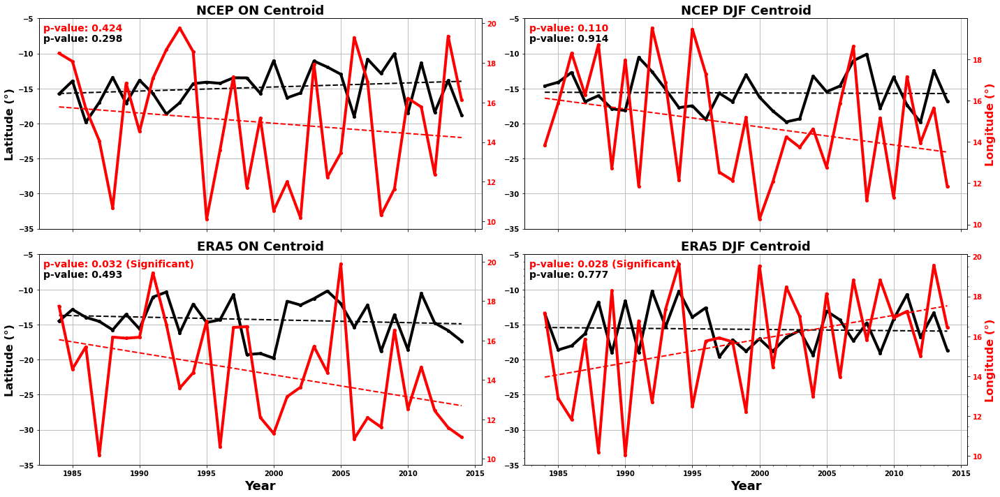

In [23]:
# Update models to use models1 list for processing
models = ['NCEP','ERA5']
          
          #'BCC-ESM1', 'HadGEM3-GC31-MM','ACCESS-CM2',
                   #'KACE-1-0-G', 'EC-Earth3-CC', 'FGOALS-g3','CanESM5', 
                   #'GFDL-ESM4','BCC-CSM2-MR','MRI-ESM2-0']  

# Update plot_info to include all models dynamically
plot_info = [(model, period_name) for model in models for period_name in periods.keys()]

# Adjust the number of subplots according to the total number of model-period combinations
n_rows = 2
n_cols = 2

# Create a dynamic grid of subplots based on the number of models and periods
fig, axs = plt.subplots(n_rows, n_cols, figsize=(20, 5 * n_rows))

# Loop over all models and periods to plot latitude on the left and longitude on the right of the same plot
for i, (model, period_name) in enumerate(plot_info):
    ax1 = axs[i // n_cols, i % n_cols]  # Select the appropriate subplot

    # Plot latitude on the left y-axis (black)
    ax1.plot(years, centroid_latitudes[model][period_name], 
             label=f'{model} {period_name} Latitude', 
             color=colors['latitude'], linestyle=line_styles[period_name], linewidth=4, marker=markers[period_name],markersize=4)

    # Compute and plot the latitude trend
    lat_slope, lat_intercept, lat_p_value = compute_trend(years, centroid_latitudes[model][period_name])
    ax1.plot(years, lat_slope * years + lat_intercept, 
             color=colors['latitude'], linestyle='--', linewidth=2, label=f'{model} {period_name} Lat Trend')

    # Annotate the p-value for the latitude trend and significance at 95%
    significance_text = f'p-value: {lat_p_value:.3f}'
    if lat_p_value < 0.05:
        significance_text += ' (Significant)'
    ax1.text(0.01, 0.89, significance_text, transform=ax1.transAxes, fontsize=14, color='black', fontweight='bold')

    # Set x-axis labels only for the bottom row
    if i // n_cols == n_rows - 1:
        ax1.set_xlabel('Year', fontsize=18, fontweight='bold')
    else:
        ax1.set_xticklabels([])  # Remove x-axis labels for other rows
    
    plt.setp(ax1.get_xticklabels(), fontweight='bold')
    
    # Set latitude limits and y-axis label
    ax1.set_ylim(-35, -5)
    if i % n_cols == 0:  # Label only the leftmost column
        ax1.set_ylabel('Latitude (°)', color=colors['latitude'], fontsize=16, fontweight='bold')
    ax1.tick_params(axis='y', labelcolor=colors['latitude'])
    
    plt.setp(ax1.get_yticklabels(), fontweight='bold')
    
    ax1.grid(True)

    # Create a second y-axis for longitude (red)
    ax2 = ax1.twinx()
    ax2.plot(years, centroid_longitudes[model][period_name], 
             label=f'{model} {period_name} Longitude', 
             color=colors['longitude'], linestyle=line_styles[period_name], linewidth=4, marker=markers[period_name],markersize=4)

    # Compute and plot the longitude trend
    lon_slope, lon_intercept, lon_p_value = compute_trend(years, centroid_longitudes[model][period_name])
    ax2.plot(years, lon_slope * years + lon_intercept, 
             color=colors['longitude'], linestyle='--', linewidth=2, label=f'{model} {period_name} Lon Trend')

    # Annotate the p-value for the longitude trend and significance at 95%
    significance_text_lon = f'p-value: {lon_p_value:.3f}'
    if lon_p_value < 0.05:
        significance_text_lon += ' (Significant)'
    ax2.text(0.01, 0.94, significance_text_lon, transform=ax2.transAxes, fontsize=14, color='red', fontweight='bold')

    # Set longitude label only for the rightmost column
    if i % n_cols == n_cols - 1:
        ax2.set_ylabel('Longitude (°)', color=colors['longitude'], fontsize=16, fontweight='bold')
    ax2.tick_params(axis='y', labelcolor=colors['longitude'])
    
    plt.setp(ax2.get_yticklabels(), fontweight='bold')
    
    # Set title
    ax1.set_title(f'{model} {period_name} Centroid', fontsize=18, fontweight='bold')

for j in range(len(plot_info), n_rows * n_cols):
    fig.delaxes(axs[j // n_cols, j % n_cols])
    
# Adjust layout for better spacing
fig.tight_layout()
fig.set_facecolor('w')

ax1.minorticks_on()
ax2.minorticks_on()
# plt.show()
#plt.savefig('interann-ERA5-NCEP.png', dpi=300, bbox_inches='tight')


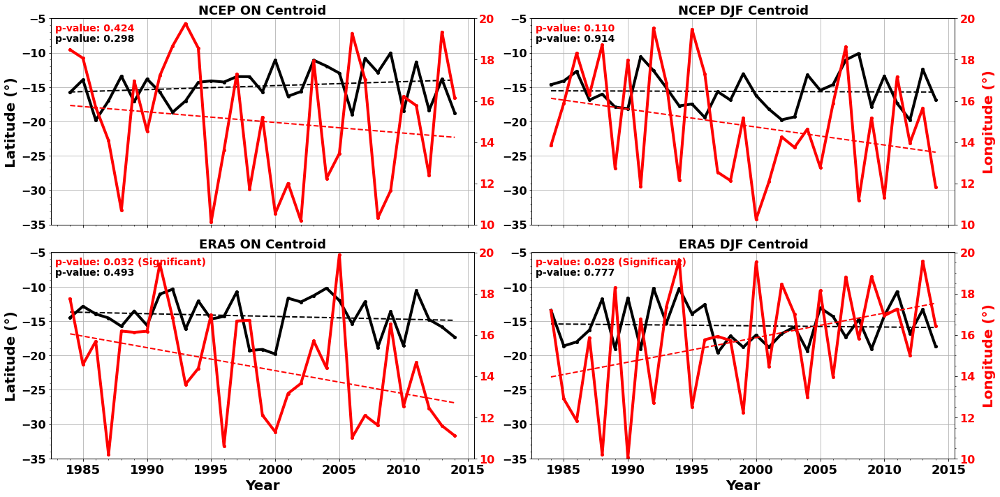

In [24]:
# Create a dynamic grid of subplots based on the number of models and periods
fig, axs = plt.subplots(n_rows, n_cols, figsize=(20, 5 * n_rows))

# Loop over all models and periods to plot latitude on the left and longitude on the right of the same plot
for i, (model, period_name) in enumerate(plot_info):
    ax1 = axs[i // n_cols, i % n_cols]  # Select the appropriate subplot

    # Plot latitude on the left y-axis (black)
    ax1.plot(years, centroid_latitudes[model][period_name], 
             label=f'{model} {period_name} Latitude', 
             color=colors['latitude'], linestyle=line_styles[period_name], linewidth=4, marker=markers[period_name], markersize=4)

    # Compute and plot the latitude trend
    lat_slope, lat_intercept, lat_p_value = compute_trend(years, centroid_latitudes[model][period_name])
    ax1.plot(years, lat_slope * years + lat_intercept, 
             color=colors['latitude'], linestyle='--', linewidth=2, label=f'{model} {period_name} Lat Trend')

    # Annotate the p-value for the latitude trend and significance at 95%
    significance_text = f'p-value: {lat_p_value:.3f}'
    if lat_p_value < 0.05:
        significance_text += ' (Significant)'
    ax1.text(0.01, 0.89, significance_text, transform=ax1.transAxes, fontsize=14, color='black', fontweight='bold')

    # Set x-axis labels only for the bottom row
    if i // n_cols == n_rows - 1:
        ax1.set_xlabel('Year', fontsize=20, fontweight='bold')
        ax1.tick_params(axis='x', labelsize=18)
    else:
        ax1.set_xticklabels([])  # Remove x-axis labels for other rows
    
    plt.setp(ax1.get_xticklabels(), fontweight='bold')
    
    # Enable minor ticks on the x-axis
    ax1.minorticks_on()  
    
    # Set latitude limits and y-axis label
    ax1.set_ylim(-35, -5)
    if i % n_cols == 0:  # Label only the leftmost column
        ax1.set_ylabel('Latitude (°)', color=colors['latitude'], fontweight='bold',fontsize=20)
    ax1.tick_params(axis='y', labelcolor=colors['latitude'],labelsize=16)
    
    plt.setp(ax1.get_yticklabels(), fontweight='bold')
    
    ax1.grid(True)

    # Create a second y-axis for longitude (red)
    ax2 = ax1.twinx()
    ax2.plot(years, centroid_longitudes[model][period_name], 
             label=f'{model} {period_name} Longitude', 
             color=colors['longitude'], linestyle=line_styles[period_name], linewidth=4, marker=markers[period_name], markersize=4)

    # Compute and plot the longitude trend
    lon_slope, lon_intercept, lon_p_value = compute_trend(years, centroid_longitudes[model][period_name])
    ax2.plot(years, lon_slope * years + lon_intercept, 
             color=colors['longitude'], linestyle='--', linewidth=2, label=f'{model} {period_name} Lon Trend')

    # Annotate the p-value for the longitude trend and significance at 95%
    significance_text_lon = f'p-value: {lon_p_value:.3f}'
    if lon_p_value < 0.05:
        significance_text_lon += ' (Significant)'
    ax2.text(0.01, 0.94, significance_text_lon, transform=ax2.transAxes, fontsize=14, color='red', fontweight='bold')

    # Set longitude label only for the rightmost column
    ax2.set_ylim(10, 20)
    if i % n_cols == n_cols - 1:
        ax2.set_ylabel('Longitude (°)', color=colors['longitude'], fontsize=20, fontweight='bold',labelpad=10)
    ax2.tick_params(axis='y', labelcolor=colors['longitude'],labelsize=16,)
    
    plt.setp(ax2.get_yticklabels(), fontweight='bold')
    
    # Set title
    ax1.set_title(f'{model} {period_name} Centroid', fontsize=18, fontweight='bold')

for j in range(len(plot_info), n_rows * n_cols):
    fig.delaxes(axs[j // n_cols, j % n_cols])
    
# Adjust layout for better spacing
fig.tight_layout()
fig.set_facecolor('w')
plt.minorticks_on()  # Enable minor ticks globally if needed

# plt.show() or save your figure
#plt.savefig('trend_ncep-ERA5.png', dpi=300, bbox_inches='tight')


In [25]:
#Monthly BH centroid

/tmp/ipykernel_133997/826301865.py:131: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


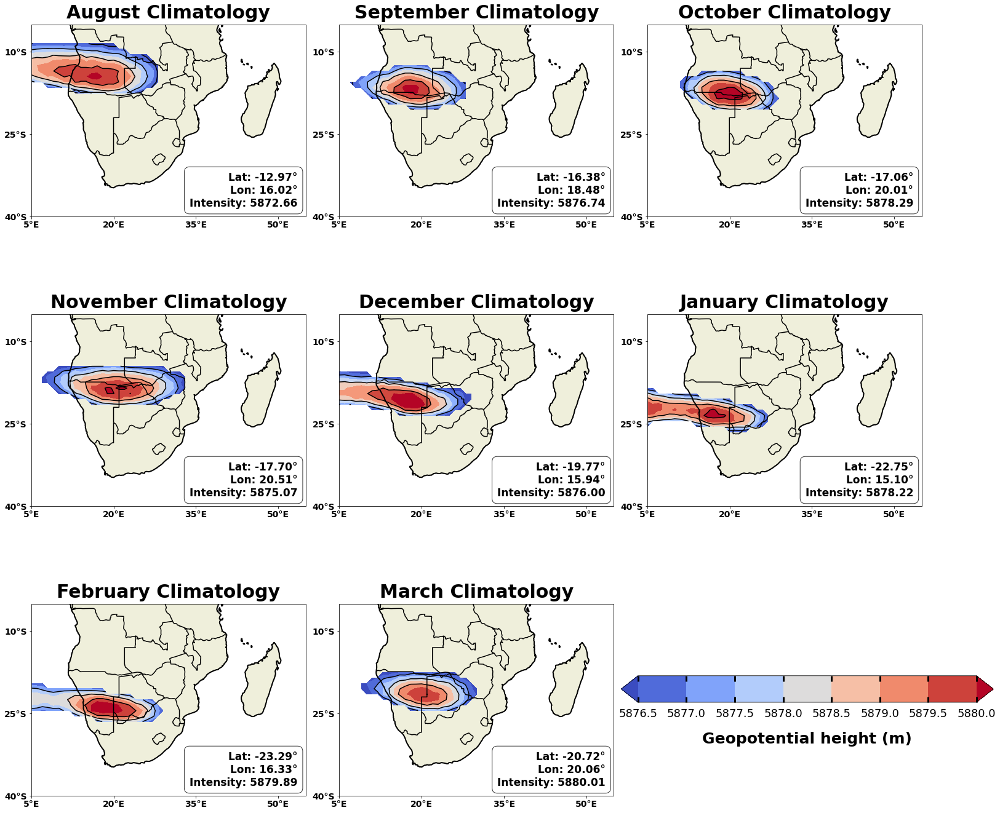

In [40]:
# Define a bold font properties object
bold_font = fm.FontProperties(weight='bold', size=14)

months = [8, 9, 10, 11, 12, 1, 2, 3]
month_names = ['August', 'September', 'October', 'November', 'December', 'January', 'February', 'March']

# Create a figure with subplots (3 rows, 3 columns), enough for 8 months
fig, axes = plt.subplots(nrows=3, ncols=3, figsize=(21, 20), subplot_kw={'projection': ccrs.PlateCarree()})

# Flatten axes for easier iteration
axes = axes.flatten()

# Hide the last unused subplot (9th) since we only need 8 subplots
axes[-1].axis('off')

# List to store intensity values for each month
intensity_values = []
int_values=[]

# Loop over each month
for i, month in enumerate(months):
    ax = axes[i]
    
    # Filter the dataset for the specific month
    ds_month = centroid['ERA5'].sel(time=centroid['ERA5']['time'].dt.month == month)
    ds_mon=centroid['ERA5'].sel(time=centroid['ERA5']['time'].dt.month==month)
    
    
    # Compute climatology for the selected month
    climatology_month = ds_month.groupby('time.year').mean(dim='time').mean(dim='year')
    clim=ds_mon.groupby('time.year').mean(dim='time').mean(dim='year')
    
    
    # Extract latitude and longitude
    latitude = centroid['ERA5']['lat']
    longitude = centroid['ERA5']['lon']

    # Maximum pressure in the climatology
    max_pressure_climatology = climatology_month.max(dim=['lat', 'lon'])
    max_pres_clim = clim.max(dim=['lat', 'lon'])
    
    
    # Define the contiguous area within 3 hPa of the maximum pressure
    threshold = 4  # 3 hPa threshold
    contiguous_area = climatology_month.where(climatology_month >= (max_pressure_climatology - threshold))
    contiguous_area = np.squeeze(contiguous_area)
    
    # Convert lat/lon to radians and calculate the cosine weighting
    latitude_radians = np.deg2rad(latitude)
    weights_latitude = np.cos(latitude_radians)

    # Apply latitude and longitude weights to compute the centroid
    weighted_latitude = (contiguous_area * weights_latitude * latitude).sum(dim=['lat', 'lon']) / \
                        (contiguous_area * weights_latitude).sum(dim=['lat', 'lon'])

    weighted_longitude = (contiguous_area * longitude).sum(dim=['lat', 'lon']) / \
                         contiguous_area.sum(dim=['lat', 'lon'])

    # Convert weighted latitude and longitude to values
    centroid_lat = weighted_latitude.values
    centroid_lon = weighted_longitude.values

    # ---- Compute Intensity ----
    # The intensity is the maximum geopotential height within the contiguous high-pressure area
    intensity = max_pressure_climatology.values
    intensity_values.append(intensity)  # Store intensity for each month
    
    int1=max_pres_clim.values
    int_values.append(int1)
    
    # ---- Plotting the contiguous area ----
    # Plot only the contiguous high-pressure area with filled contours
    contour = ax.contourf(longitude, latitude, contiguous_area, cmap='coolwarm', transform=ccrs.PlateCarree(), extend='both', levels=8)
    
    # Add contour lines and label only 3 specific contour levels
    contours = ax.contour(longitude, latitude, contiguous_area, colors='black', levels=3, transform=ccrs.PlateCarree())

    # Add coastlines and features
    ax.coastlines(linewidth=2)
    ax.add_feature(cfeature.BORDERS,linewidth=1.5)
    ax.add_feature(cfeature.LAND, edgecolor='black')

    # Plot the centroid position
    #ax.plot(centroid_lon, centroid_lat, marker='o', color='black', markersize=12, transform=ccrs.PlateCarree())

    # Set title for each month
    ax.set_title(f'{month_names[i]} Climatology', fontsize=30, fontweight='bold', pad=10)
    
    ax.set_extent((5, 55, -5, -40), crs=ccrs.PlateCarree())
    
    # Set latitude and longitude ticks
    ax.set_yticks(np.arange(-40, -5, 15), crs=ccrs.PlateCarree())
    lat_formatter = mticker.LatitudeFormatter()
    ax.yaxis.set_major_formatter(lat_formatter)
    
    for label in ax.get_yticklabels():
        label.set_fontproperties(bold_font)
    
    ax.set_xticks(np.arange(5, 55, 15), crs=ccrs.PlateCarree())
    lon_formatter = mticker.LongitudeFormatter()
    ax.xaxis.set_major_formatter(lon_formatter)
    
    for label in ax.get_xticklabels():
        label.set_fontproperties(bold_font)
        
    # Add centroid latitude, longitude, and intensity text
    # Convert to scalar values
    # Convert to scalar values
    centroid_lat_value = centroid_lat.item() if isinstance(centroid_lat, np.ndarray) else centroid_lat.values.item()
    centroid_lon_value = centroid_lon.item() if isinstance(centroid_lon, np.ndarray) else centroid_lon.values.item()
    intensity_value = intensity.item() if isinstance(intensity, np.ndarray) else intensity

# Add centroid latitude, longitude, and intensity text
    ax.text(0.97, 0.04, f'Lat: {centroid_lat_value:.2f}°\nLon: {centroid_lon_value:.2f}°\nIntensity: {intensity_value:.2f}',
        horizontalalignment='right', verticalalignment='bottom', 
        transform=ax.transAxes, fontsize=17, color='black', fontweight='bold', 
        bbox=dict(facecolor='white', alpha=0.8, boxstyle='round,pad=0.5'))



# Adjust layout and add colorbar
fig.subplots_adjust(hspace=0.4, wspace=0.4)  # Adjust the space between subplots
cbar_ax = fig.add_axes([0.67, 0.17, 0.4, 0.03])  # Colorbar position

# Set the colorbar to reflect the mean geopotential height
cbar = fig.colorbar(contour, cax=cbar_ax, orientation='horizontal', fraction=0.02, pad=0.8)
cbar.ax.tick_params(axis='x', direction='in', length=9, width=3, colors='k', top=True, labelsize=18, pad=10)
cbar.set_label('Geopotential height (m)', fontsize=25, fontweight='bold', labelpad=20)


plt.tight_layout()
fig.set_facecolor('w')

# Show the map plots
#plt.show()

#plt.savefig('ERA5_MON2.png', dpi=300, bbox_inches='tight')


In [27]:
#NCEP,ERA5 INTENSITY

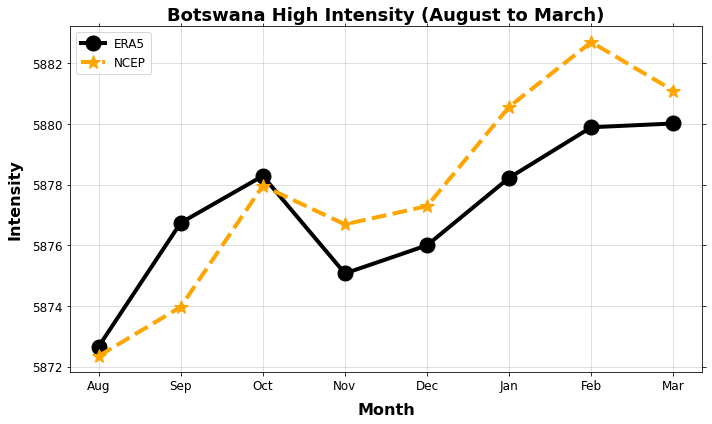

In [28]:

# Define the months for August to March (1-indexed for clarity)
months = [8, 9, 10, 11, 12, 1, 2, 3]  # August to March
month_names = ['Aug', 'Sep', 'Oct', 'Nov', 'Dec', 'Jan', 'Feb', 'Mar']

# Initialize intensity values for ERA5
intensity_values = []

# Calculate ERA5 intensity values for each month
for month in months:
    ds_month_era5 = centroid['ERA5'].sel(time=centroid['ERA5']['time'].dt.month == month)
    climatology_month_era5 = ds_month_era5.groupby('time.year').mean(dim='time').mean(dim='year')
    max_pressure_climatology_era5 = climatology_month_era5.max(dim=['lat', 'lon'])
    intensity_values.append(max_pressure_climatology_era5.values)

# Initialize intensity values for NCEP
int1 = []  # NCEP intensity values list

# Calculate NCEP intensity values for each month
for month in months:
    ds_month_ncep = centroid['NCEP'].sel(time=centroid['NCEP']['time'].dt.month == month)
    climatology_month_ncep = ds_month_ncep.groupby('time.year').mean(dim='time').mean(dim='year')
    max_pressure_climatology_ncep = climatology_month_ncep.max(dim=['lat', 'lon'])
    int1.append(max_pressure_climatology_ncep.values)

# Ensure int1 has the same length as month_names
if len(int1) == 1:
    int1 = [int1[0]] * len(month_names)  # Repeat the single value for all months

# Plot intensity over time (August to March)
plt.figure(figsize=(10, 6))
fig.patch.set_facecolor('w')
plt.plot(month_names, intensity_values, marker='o', color='black', linestyle='-', linewidth=4, markersize=15, label='ERA5')
plt.plot(month_names, int1, marker='*', color='orange', linestyle='--', linewidth=4, markersize=15, label='NCEP')

# Add labels and title
plt.xlabel('Month', fontsize=16, fontweight='bold', labelpad=10)
plt.ylabel('Intensity', fontsize=16, fontweight='bold', labelpad=10)
plt.title('Botswana High Intensity (August to March)', fontsize=18, fontweight='bold')
plt.xticks(fontsize=12)
plt.yticks(fontsize=12)
plt.legend(fontsize=12)
plt.grid(alpha=0.5)
plt.tick_params(top=True,right=True)

fig.set_facecolor('w')
plt.tight_layout()

#plt.savefig('ERA5_NCEP_Intensity.png', dpi=300, bbox_inches='tight')


In [29]:
#CMIP6 models BH Intensity 

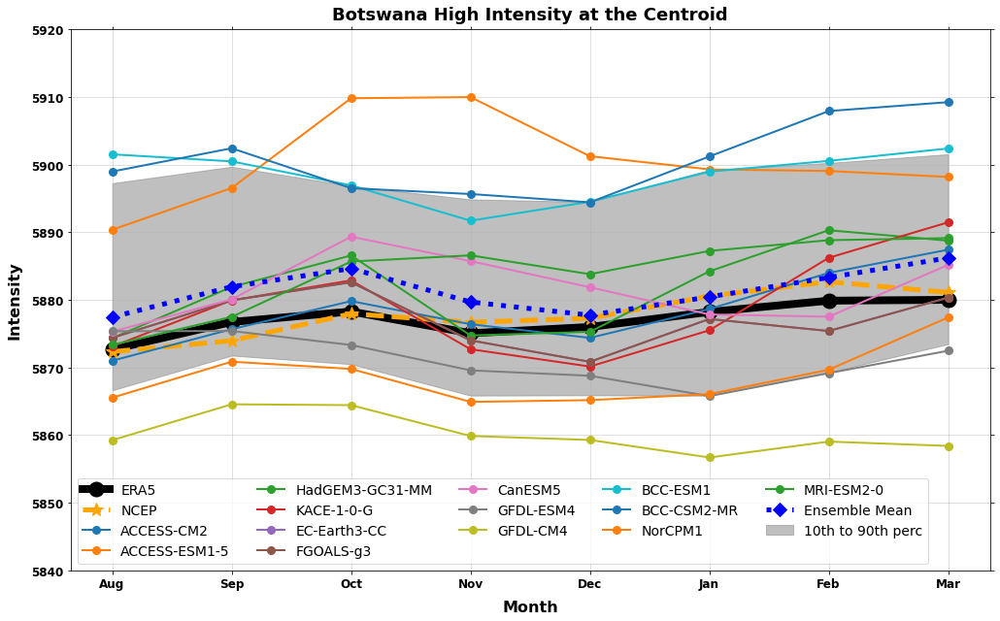

In [30]:
import matplotlib.pyplot as plt
import numpy as np
import xarray as xr

# Define the months for August to March
months = [8, 9, 10, 11, 12, 1, 2, 3]  # August to March
month_names = ['Aug', 'Sep', 'Oct', 'Nov', 'Dec', 'Jan', 'Feb', 'Mar']

# Initialize intensity values for ERA5
intensity_values = []

# Calculate ERA5 intensity values for each month
for month in months:
    ds_month_era5 = centroid['ERA5'].sel(time=centroid['ERA5']['time'].dt.month == month)
    climatology_month_era5 = ds_month_era5.groupby('time.year').mean(dim='time').mean(dim='year')
    max_pressure_climatology_era5 = climatology_month_era5.max(dim=['lat', 'lon'])
    intensity_values.append(max_pressure_climatology_era5.values)

# Initialize intensity values for NCEP
int1 = []  # NCEP intensity values list

# Calculate NCEP intensity values for each month
for month in months:
    ds_month_ncep = centroid['NCEP'].sel(time=centroid['NCEP']['time'].dt.month == month)
    climatology_month_ncep = ds_month_ncep.groupby('time.year').mean(dim='time').mean(dim='year')
    max_pressure_climatology_ncep = climatology_month_ncep.max(dim=['lat', 'lon'])
    int1.append(max_pressure_climatology_ncep.values)

# Ensure int1 has the same length as month_names
if len(int1) == 1:
    int1 = [int1[0]] * len(month_names)  # Repeat the single value for all months

# Initialize intensity values for models
models = ['ACCESS-CM2', 'ACCESS-ESM1-5', 'HadGEM3-GC31-MM',
                   'KACE-1-0-G', 'EC-Earth3-CC', 'FGOALS-g3','CanESM5', 
                   'GFDL-ESM4','GFDL-CM4','BCC-ESM1','BCC-CSM2-MR',
          'NorCPM1','MRI-ESM2-0']
model_intensities = {model: [] for model in models}

# Calculate intensity values for each model
for model in models:
    for month in months:
        ds_month_model = centroid[model].sel(time=centroid[model]['time'].dt.month == month)
        climatology_month_model = ds_month_model.groupby('time.year').mean(dim='time').mean(dim='year')
        max_pressure_climatology_model = climatology_month_model.max(dim=['lat', 'lon'])
        model_intensities[model].append(max_pressure_climatology_model.values)

# Calculate ensemble mean intensity for the models
ensemble_mean = np.mean([model_intensities[model] for model in models], axis=0)

# Calculate percentiles (10th and 90th)
percentiles_10th = np.percentile(np.array([model_intensities[model] for model in models]), 10, axis=0)
percentiles_90th = np.percentile(np.array([model_intensities[model] for model in models]), 90, axis=0)


# Plot intensity over time (August to March)
plt.figure(figsize=(15, 9))
plt.plot(month_names, intensity_values, marker='o', color='black', linestyle='-', linewidth=8, markersize=15, label='ERA5')
plt.plot(month_names, int1, marker='*', color='orange', linestyle='--', linewidth=5, markersize=15, label='NCEP')

# Plot each model intensity
for model in models:
    plt.plot(month_names, model_intensities[model], marker='o', linestyle='-', linewidth=2, markersize=8, label=model)

# Plot ensemble mean intensity
plt.plot(month_names, ensemble_mean, marker='D', color='blue', linestyle=':', linewidth=5, markersize=10, label='Ensemble Mean')
# Fill the area between the 10th and 90th percentiles
tenth=percentiles_10th.flatten()
ninety=percentiles_90th.flatten()

plt.fill_between(month_names,tenth, ninety, color='grey', alpha=0.5, label='10th to 90th perc')

# Add labels and title
plt.xlabel('Month', fontsize=16, fontweight='bold', labelpad=10)
plt.ylabel('Intensity', fontsize=16, fontweight='bold', labelpad=10)
plt.title('Botswana High Intensity at the Centroid', fontsize=18, fontweight='bold',pad=10)
plt.ylim(5840,5920)
plt.xticks(fontsize=12,fontweight='bold')
plt.yticks(fontsize=12,fontweight='bold')
plt.legend(fontsize=14, ncol=5, loc='lower left')
plt.grid(alpha=0.5)
plt.tick_params(top=True, right=True)

# Set figure face color
plt.gcf().patch.set_facecolor('w')  # Set the figure background color
plt.tight_layout()

#plt.savefig('Intensity_models.png', dpi=300, bbox_inches='tight')


/tmp/ipykernel_1619862/4294073386.py:26: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax1.set_yticklabels([f'{y:.0f}' for y in ax1.get_yticks()], fontsize=20, fontweight='bold')
/tmp/ipykernel_1619862/4294073386.py:49: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax2.set_yticklabels([f'{y:.0f}' for y in ax2.get_yticks()], fontsize=20, fontweight='bold')


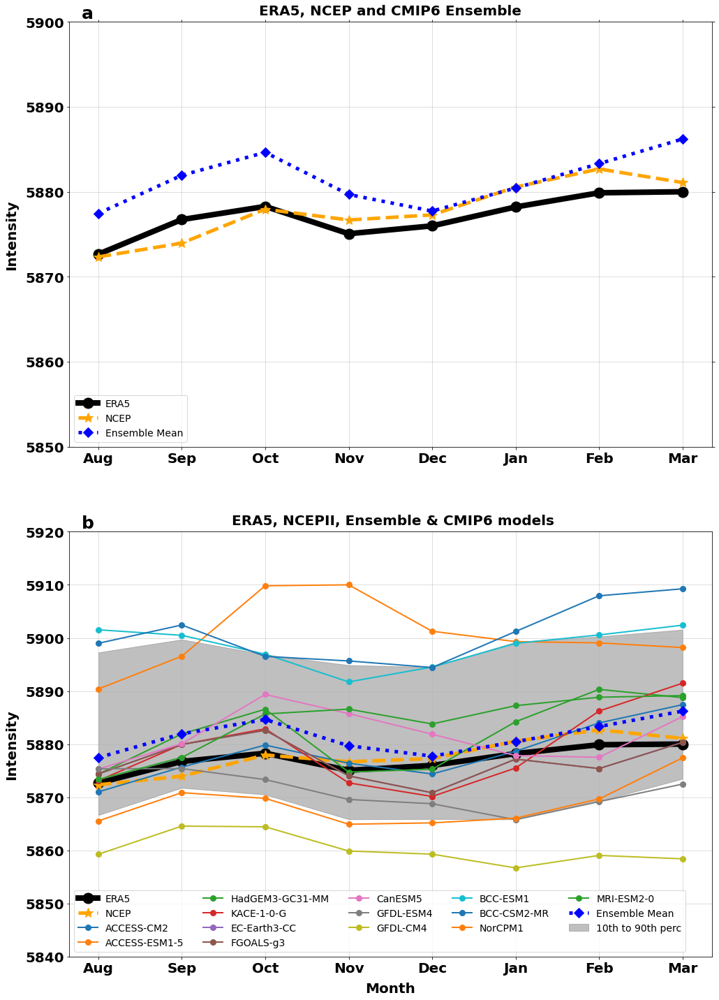

In [31]:
import matplotlib.pyplot as plt
import numpy as np

# Define figure and subplots
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(15, 20))

# Subplot a: Only ERA5, NCEP, and Ensemble Mean
ax1.plot(month_names, intensity_values, marker='o', color='black', linestyle='-', linewidth=8, markersize=15, label='ERA5')
ax1.plot(month_names, int1, marker='*', color='orange', linestyle='--', linewidth=5, markersize=15, label='NCEP')
ax1.plot(month_names, ensemble_mean, marker='D', color='blue', linestyle=':', linewidth=5, markersize=10, label='Ensemble Mean')

# Fill between 10th and 90th percentiles for ensemble
#ax1.fill_between(month_names, percentiles_10th.flatten(), percentiles_90th.flatten(), color='grey', alpha=0.5, label='10th to 90th perc')

# Add labels, title, and settings for subplot a
#ax1.set_xlabel('Month', fontsize=16, fontweight='bold', labelpad=10)
ax1.set_ylabel('Intensity', fontsize=20, fontweight='bold', labelpad=10)
ax1.set_title('ERA5, NCEP and CMIP6 Ensemble', fontsize=20, fontweight='bold', pad=10)
ax1.set_ylim(5850, 5900)
ax1.set_xticks(np.arange(len(month_names)))
ax1.set_xticklabels(month_names, fontsize=20, fontweight='bold')
ax1.legend(fontsize=14, loc='lower left')
ax1.grid(alpha=0.5)
ax1.tick_params(top=True, right=True)
ax1.set_xticklabels(month_names, fontsize=20, fontweight='bold')
ax1.set_yticklabels([f'{y:.0f}' for y in ax1.get_yticks()], fontsize=20, fontweight='bold')

# Subplot b: ERA5, NCEP, Ensemble Mean, and all models
ax2.plot(month_names, intensity_values, marker='o', color='black', linestyle='-', linewidth=8, markersize=15, label='ERA5')
ax2.plot(month_names, int1, marker='*', color='orange', linestyle='--', linewidth=5, markersize=15, label='NCEP')

# Plot each model intensity on subplot b
for model in models:
    ax2.plot(month_names, model_intensities[model], marker='o', linestyle='-', linewidth=2, markersize=8, label=model)

# Plot ensemble mean intensity
ax2.plot(month_names, ensemble_mean, marker='D', color='blue', linestyle=':', linewidth=5, markersize=10, label='Ensemble Mean')

# Fill between 10th and 90th percentiles for ensemble
ax2.fill_between(month_names, percentiles_10th.flatten(), percentiles_90th.flatten(), color='grey', alpha=0.5, label='10th to 90th perc')

# Add labels, title, and settings for subplot b
ax2.set_xlabel('Month', fontsize=20, fontweight='bold', labelpad=10)
ax2.set_ylabel('Intensity', fontsize=20, fontweight='bold', labelpad=10)
ax2.set_title(' ERA5, NCEPII, Ensemble & CMIP6 models', fontsize=20, fontweight='bold', pad=10)
ax2.set_ylim(5840, 5920)
ax2.set_xticks(np.arange(len(month_names)))
ax2.set_xticklabels(month_names, fontsize=20, fontweight='bold')
ax2.set_yticklabels([f'{y:.0f}' for y in ax2.get_yticks()], fontsize=20, fontweight='bold')
ax2.grid(alpha=0.5)
#ax2.tick_params(top=True, right=True)
ax2.legend(fontsize=14, ncol=5, loc='lower left')
# Adjust layout and set face color for the figure
plt.gcf().patch.set_facecolor('w')
plt.tight_layout()

ax1.text(0.02, 1.04, 'a', transform=ax1.transAxes, fontsize=25, fontweight='bold', verticalalignment='top')
ax2.text(0.02, -0.16, 'b', transform=ax1.transAxes, fontsize=25, fontweight='bold', verticalalignment='top')

fig.subplots_adjust(hspace=0.2)
# Show the plot
#plt.show()

#plt.savefig('Intensity_re_models_subplot_latest.png', dpi=300, bbox_inches='tight')


In [32]:
#BH correlation dsp

In [47]:
import numpy as np
import xarray as xr

# Assuming centroid and on_months are defined earlier in your script
# on_months should be a list of months for the ON season, e.g., [10, 11]

# Example for ON months (October, November)
on_months = [10, 11]

# Dictionary to store ERA5 intensity values for ON season
era5_intensity = []

# Iterate over each unique year in the ERA5 dataset
for year in np.unique(centroid['ERA5']['time'].dt.year):
    # Create a combined boolean condition for both year and months
    time_condition = (centroid['ERA5']['time'].dt.year == year) & (centroid['ERA5']['time'].dt.month.isin(on_months))
    
    # Apply the combined condition to select the data for the ON season in that year
    ds_on_era5 = centroid['ERA5'].sel(time=time_condition)
    
    # Calculate the climatology for the ON season by averaging over the time dimension
    climatology_on_era5 = ds_on_era5.groupby('time.year').mean(dim='time')
    
    # Find the maximum pressure over the lat-lon grid for that season
    max_pressure_climatology_era5 = climatology_on_era5.max(dim=['lat', 'lon'])
    
    # Store the result in the list (or process further as needed)
    era5_intensity.append(max_pressure_climatology_era5)

# Convert the list of results into a DataArray or other structure if needed
era5_intensity = xr.concat(era5_intensity, dim='year')

# Further processing or visualization if necessary
# e.g., plotting or saving the results to a file

time_condition = (centroid['ERA5']['time'].dt.year == year) & (centroid['ERA5']['time'].dt.month.isin(on_months))
ds_on_era5 = centroid['ERA5'].sel(time=time_condition)
climatology_on_era5 = ds_on_era5.groupby('time.year').mean(dim='time')
max_pressure_climatology_era5 = climatology_on_era5.max(dim=['lat', 'lon'])
era5_intensity = xr.concat(era5_intensity, dim='year')


In [48]:
era5_intensity

<xarray.DataArray 'ERA5' (year: 31)> Size: 124B
array([5868.336, 5862.59 , 5867.379, 5884.619, 5871.211, 5875.998,
       5886.535, 5870.252, 5874.084, 5879.828, 5875.041, 5878.871,
       5875.041, 5878.873, 5884.619, 5869.295, 5872.168, 5876.957,
       5881.746, 5882.703, 5884.619, 5884.619, 5881.746, 5873.125,
       5884.619, 5876.957, 5880.787, 5873.125, 5884.619, 5881.746,
       5885.576], dtype=float32)
Coordinates:
  * year     (year) int64 248B 1984 1985 1986 1987 1988 ... 2011 2012 2013 2014

In [49]:
import numpy as np
import xarray as xr

# List of all models
models = ['ERA5','NCEP', 'ACCESS-CM2', 'ACCESS-ESM1-5', 'HadGEM3-GC31-MM',
          'KACE-1-0-G', 'EC-Earth3-CC', 'FGOALS-g3', 'CanESM5', 'GFDL-ESM4',
          'IPSL-CM6A-LR', 'MIROC6']

# Subset of models for ensemble
ensemble_models = ['ACCESS-CM2', 'ACCESS-ESM1-5', 'HadGEM3-GC31-MM',
                   'KACE-1-0-G', 'EC-Earth3-CC', 'FGOALS-g3', 'CanESM5', 
                   'GFDL-ESM4', 'IPSL-CM6A-LR', 'MIROC6']

# ON months (October, November)
on_months = [10, 11]

# Dictionary to store intensity values for each model
model_intensity = {}

# Iterate over each model to compute the intensity for ON months
for model in models:
    model_intensity[model] = []
    
    # Assuming `centroid[model]` contains the data for each model
    for year in np.unique(centroid[model]['time'].dt.year):
        # Create a combined boolean condition for both year and months
        time_condition = (centroid[model]['time'].dt.year == year) & (centroid[model]['time'].dt.month.isin(on_months))
        
        # Apply the combined condition to select the data for the ON season in that year
        ds_on_model = centroid[model].sel(time=time_condition)
        
        # Calculate the climatology for the ON season by averaging over the time dimension
        climatology_on_model = ds_on_model.groupby('time.year').mean(dim='time')
        
        # Find the maximum pressure over the lat-lon grid for that season
        max_pressure_climatology_model = climatology_on_model.max(dim=['lat', 'lon'])
        
        # Store the result in the list for that model
        model_intensity[model].append(max_pressure_climatology_model)

    # Convert the list of results for this model into a DataArray
    model_intensity[model] = xr.concat(model_intensity[model], dim='year')

# Initialize a list to hold all model intensity data arrays
all_models_data = []

# Concatenate all models' data into a single DataArray
for model in models:
    all_models_data.append(model_intensity[model])

# Create a single DataArray for all models
all_models_combined = xr.concat(all_models_data, dim='model')

# Assign model names as coordinates
all_models_combined = all_models_combined.assign_coords(model=('model', models))

# Now compute the ensemble mean for the subset of models
ensemble_data = xr.concat([model_intensity[model] for model in ensemble_models], dim='model',coords='minimal')

# Calculate the ensemble mean
ensemble_mean = ensemble_data.mean(dim='model')

# Create a new DataArray for the ensemble mean
ensemble_mean = ensemble_mean.rename("ensemble_mean")

# Add the ensemble mean to the combined DataArray, with a distinct name
ensemble_mean = ensemble_mean.expand_dims('model')
ensemble_mean = ensemble_mean.assign_coords(model=['Ensemble'])

# Concatenate ensemble mean to the all models combined DataArray
final_combined = xr.concat([all_models_combined, ensemble_mean], dim='model')

# Add a name for the combined DataArray for clarity
final_combined = final_combined.rename("maximum_pressure_climatology")

# Further processing or visualization
# e.g., plotting or saving the results to a file

# Display the final combined DataArray
print(final_combined)



<xarray.DataArray 'maximum_pressure_climatology' (model: 13, year: 31,
                                                  level: 1, plev: 1, plev_2: 1)> Size: 2kB
array([[[[[5868.336 ]]],


        [[[5862.59  ]]],


        [[[5867.379 ]]],


        [[[5884.619 ]]],


        [[[5871.211 ]]],


        [[[5875.998 ]]],


        [[[5886.535 ]]],

...

        [[[5880.6465]]],


        [[[5883.378 ]]],


        [[[5882.831 ]]],


        [[[5878.0107]]],


        [[[5888.096 ]]],


        [[[5886.628 ]]],


        [[[5885.413 ]]]]], dtype=float32)
Coordinates:
  * year     (year) int64 248B 1984 1985 1986 1987 1988 ... 2011 2012 2013 2014
  * level    (level) float32 4B 500.0
  * plev     (plev) float64 8B 5e+04
  * plev_2   (plev_2) float64 8B 5e+04
  * model    (model) <U15 780B 'ERA5' 'NCEP' ... 'MIROC6' 'Ensemble'


In [50]:
ON_DSP=xr.open_dataset('/data/strato/jupyter/Ramugondo/ON_DSP_merged.nc')
ON_DSP

<xarray.Dataset> Size: 201MB
Dimensions:        (time: 31, bnds: 2, lon: 360, lat: 180)
Coordinates:
  * time           (time) datetime64[ns] 248B 1984-10-31 ... 2014-11-02T12:00:00
  * lon            (lon) float64 3kB 0.0 1.0 2.0 3.0 ... 356.0 357.0 358.0 359.0
  * lat            (lat) float64 1kB -89.5 -88.5 -87.5 -86.5 ... 87.5 88.5 89.5
Dimensions without coordinates: bnds
Data variables: (12/26)
    time_bnds      (time, bnds) datetime64[ns] 496B ...
    ACCESS-CM2     (time, lat, lon) float32 8MB ...
    ACCESS-ESM1-5  (time, lat, lon) float32 8MB ...
    CESM2-WACCM    (time, lat, lon) float32 8MB ...
    CESM2          (time, lat, lon) float32 8MB ...
    CMCC-ESM2      (time, lat, lon) float32 8MB ...
    ...             ...
    MIROC6         (time, lat, lon) float32 8MB ...
    MPI-ESM1-2-LR  (time, lat, lon) float32 8MB ...
    MRI-ESM2-0     (time, lat, lon) float32 8MB ...
    NorESM2-LM     (time, lat, lon) float32 8MB ...
    NorESM2-MM     (time, lat, lon) float32 8MB ...
    TaiESM1        (time, lat, lon) float32 8MB ...
Attributes: (12/48)
    CDI:                    Climate Data Interface version 2.0.5 (https://mpi...
    Conventions:            CF-1.7 CMIP-6.2
    activity_id:            CMIP
    branch_method:          standard
    branch_time_in_child:   0.0
    branch_time_in_parent:  0.0
    ...                     ...
    cmor_version:           3.4.0
    tracking_id:            hdl:21.14100/27a2a033-bc7e-45ff-8c30-02bf65722aaf
    license:                CMIP6 model data produced by CSIRO is licensed un...
    NCO:                    netCDF Operators version 5.0.1 (Homepage = http:/...
    history:                Mon Aug 07 22:28:52 2023: cdo merge DSP_ON_ACCESS...
    CDO:                    Climate Data Operators version 2.0.5 (https://mpi...

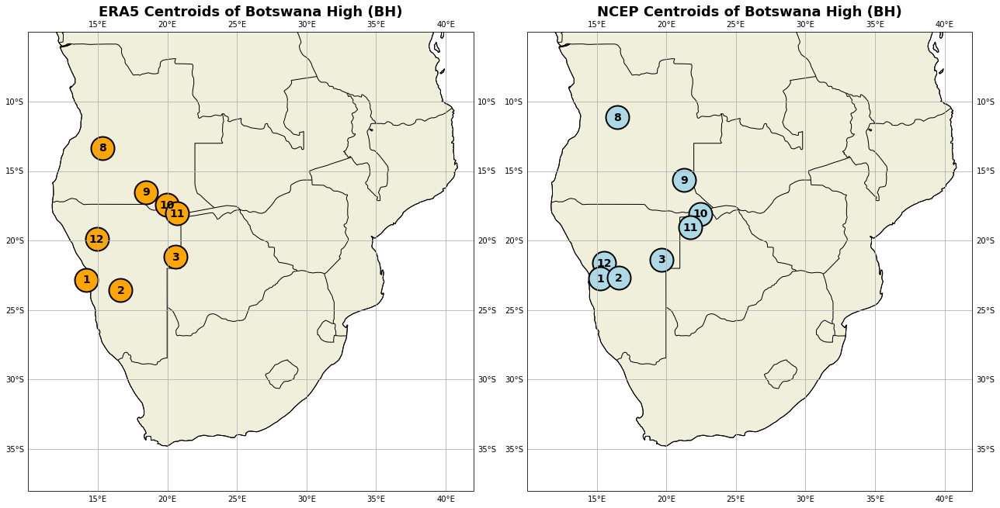

In [51]:
import matplotlib.pyplot as plt
import cartopy.crs as ccrs
import cartopy.feature as cfeature
import numpy as np

# Create a figure with two subplots (one for ERA5 and one for NCEP)
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(18, 10), subplot_kw={'projection': ccrs.PlateCarree()})

# Define months and corresponding names
months = [8, 9, 10, 11, 12, 1, 2, 3]
month_names = ['August', 'September', 'October', 'November', 'December', 'January', 'February', 'March']

# Initialize lists to store centroid latitudes and longitudes for each dataset (ERA5 and NCEP)
centroid_lats_era5 = []
centroid_lons_era5 = []
centroid_lats_ncep = []
centroid_lons_ncep = []

# Loop over each month and calculate the centroids for ERA5
for month in months:
    # Filter the ERA5 dataset for the specific month
    ds_month_era5 = centroid['ERA5'].sel(time=centroid['ERA5']['time'].dt.month == month)
    
    # Compute climatology for the selected month
    climatology_month_era5 = ds_month_era5.groupby('time.year').mean(dim='time').mean(dim='year')

    # Maximum pressure in the climatology
    max_pressure_climatology_era5 = climatology_month_era5.max(dim=['lat', 'lon'])

    # Define the contiguous area within 3 hPa of the maximum pressure
    threshold = 3
    contiguous_area_era5 = climatology_month_era5.where(climatology_month_era5 >= (max_pressure_climatology_era5 - threshold))
    contiguous_area_era5 = np.squeeze(contiguous_area_era5)
    
    # Convert lat/lon to radians and calculate the cosine weighting
    latitude_radians = np.deg2rad(centroid['lat'])
    weights_latitude = np.cos(latitude_radians)

    # Apply latitude and longitude weights to compute the centroid
    weighted_latitude_era5 = (contiguous_area_era5 * weights_latitude * centroid['lat']).sum(dim=['lat', 'lon']) / \
                             (contiguous_area_era5 * weights_latitude).sum(dim=['lat', 'lon'])
    weighted_longitude_era5 = (contiguous_area_era5 * centroid['lon']).sum(dim=['lat', 'lon']) / \
                              contiguous_area_era5.sum(dim=['lat', 'lon'])

    # Store the computed centroids
    centroid_lats_era5.append(weighted_latitude_era5.values)
    centroid_lons_era5.append(weighted_longitude_era5.values)

# Loop over each month and calculate the centroids for NCEP
for month in months:
    # Filter the NCEP dataset for the specific month
    ds_month_ncep = centroid['KACE-1-0-G'].sel(time=centroid['KACE-1-0-G']['time'].dt.month == month)
    
    # Compute climatology for the selected month
    climatology_month_ncep = ds_month_ncep.groupby('time.year').mean(dim='time').mean(dim='year')

    # Maximum pressure in the climatology
    max_pressure_climatology_ncep = climatology_month_ncep.max(dim=['lat', 'lon'])

    # Define the contiguous area within 3 hPa of the maximum pressure
    threshold = 3
    contiguous_area_ncep = climatology_month_ncep.where(climatology_month_ncep >= (max_pressure_climatology_ncep - threshold))
    contiguous_area_ncep = np.squeeze(contiguous_area_ncep)
    
    # Convert lat/lon to radians and calculate the cosine weighting
    latitude_radians = np.deg2rad(centroid['lat'])
    weights_latitude = np.cos(latitude_radians)

    # Apply latitude and longitude weights to compute the centroid
    weighted_latitude_ncep = (contiguous_area_ncep * weights_latitude * centroid['lat']).sum(dim=['lat', 'lon']) / \
                             (contiguous_area_ncep * weights_latitude).sum(dim=['lat', 'lon'])
    weighted_longitude_ncep = (contiguous_area_ncep * centroid['lon']).sum(dim=['lat', 'lon']) / \
                              contiguous_area_ncep.sum(dim=['lat', 'lon'])

    # Store the computed centroids
    centroid_lats_ncep.append(weighted_latitude_ncep.values)
    centroid_lons_ncep.append(weighted_longitude_ncep.values)

# Plot ERA5 Centroids
ax1.set_extent((10, 42, -5, -38), crs=ccrs.PlateCarree())
ax1.coastlines()
ax1.add_feature(cfeature.BORDERS)
ax1.add_feature(cfeature.LAND, edgecolor='black')

for i, month in enumerate(months):
    ax1.plot(centroid_lons_era5[i], centroid_lats_era5[i], marker='o', markersize=30, markerfacecolor='orange',
             markeredgewidth=2, markeredgecolor='black', transform=ccrs.PlateCarree())
    ax1.text(centroid_lons_era5[i], centroid_lats_era5[i], str(month), horizontalalignment='center',
             verticalalignment='center', fontsize=14, fontweight='bold', color='black',
             transform=ccrs.PlateCarree())

ax1.set_title('ERA5 Centroids of Botswana High (BH)', fontsize=18, fontweight='bold')
ax1.gridlines(draw_labels=True)

# Plot NCEP Centroids
ax2.set_extent((10, 42, -5, -38), crs=ccrs.PlateCarree())
ax2.coastlines()
ax2.add_feature(cfeature.BORDERS)
ax2.add_feature(cfeature.LAND, edgecolor='black')

for i, month in enumerate(months):
    ax2.plot(centroid_lons_ncep[i], centroid_lats_ncep[i], marker='o', markersize=30, markerfacecolor='lightblue',
             markeredgewidth=2, markeredgecolor='black', transform=ccrs.PlateCarree())
    ax2.text(centroid_lons_ncep[i], centroid_lats_ncep[i], str(month), horizontalalignment='center',
             verticalalignment='center', fontsize=14, fontweight='bold', color='black',
             transform=ccrs.PlateCarree())

ax2.set_title('NCEP Centroids of Botswana High (BH)', fontsize=18, fontweight='bold')
ax2.gridlines(draw_labels=True)

# Show the plot
plt.tight_layout()
plt.show()



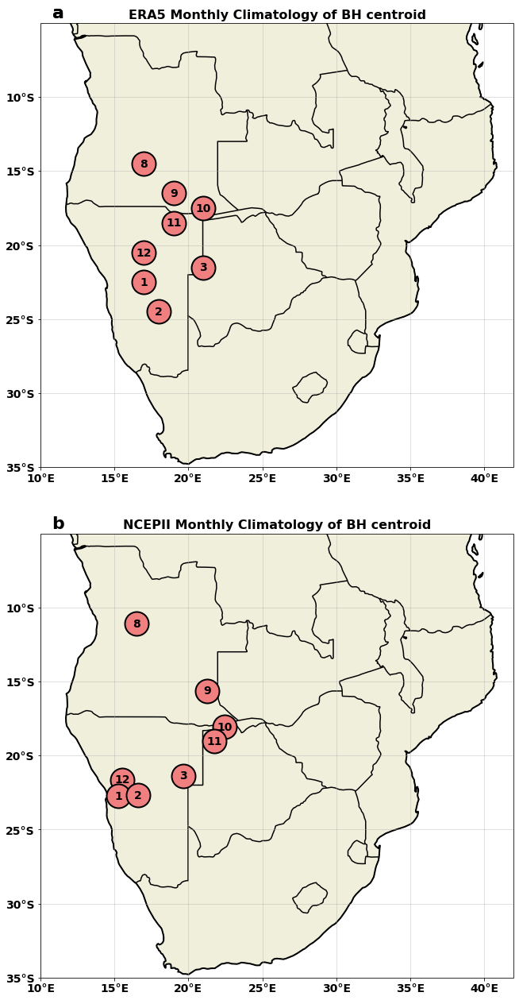

In [52]:
import matplotlib.pyplot as plt
import cartopy.crs as ccrs
import cartopy.feature as cfeature
import numpy as np

# Function to wrap longitudes if necessary (from 0-360 to -180 to 180)
def wrap_longitudes(lon):
    return np.where(lon > 180, lon - 360, lon)

# Create a figure with two subplots (one for ERA5 and one for NCEP)
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(9,18), subplot_kw={'projection': ccrs.PlateCarree()})

# Define months and corresponding names
months = [8, 9, 10, 11, 12, 1, 2, 3]
month_names = ['August', 'September', 'October', 'November', 'December', 'January', 'February', 'March']

# Initialize lists to store maximum pressure latitudes and longitudes for each dataset (ERA5 and NCEP)
max_lats_era5 = []
max_lons_era5 = []
max_lats_ncep = []
max_lons_ncep = []

# Loop over each month and calculate the location of maximum pressure for ERA5
for month in months:
    # Filter the ERA5 dataset for the specific month
    ds_month_era5 = centroid['ERA5'].sel(time=centroid['ERA5']['time'].dt.month == month)
    
    # Compute climatology for the selected month
    climatology_month_era5 = ds_month_era5.groupby('time.year').mean(dim='time').mean(dim='year')

    # Find the lat/lon where the maximum pressure occurs
    max_idx_era5 = np.unravel_index(climatology_month_era5.argmax(), climatology_month_era5.shape)
    max_lat_era5 = centroid['lat'][max_idx_era5[0]].values
    max_lon_era5 = centroid['lon'][max_idx_era5[1]].values

    # Store the max pressure location
    max_lats_era5.append(max_lat_era5)
    max_lons_era5.append(max_lon_era5)

# Loop over each month and calculate the location of maximum pressure for NCEP
for month in months:
    # Filter the NCEP dataset for the specific month
    ds_month_ncep1 = centroid['NCEP'].sel(time=centroid['NCEP']['time'].dt.month == month)
    
    # Compute climatology for the selected month
    climatology_month_ncep = ds_month_ncep1.groupby('time.year').mean(dim='time').mean(dim='year')

    # Find the lat/lon where the maximum pressure occurs
    max_idx_ncep = np.unravel_index(climatology_month_ncep.argmax(), climatology_month_ncep.shape)
    max_lat_ncep = centroid['lat'][max_idx_ncep[0]].values
    max_lon_ncep = centroid['lon'][max_idx_ncep[1]].values

    # Wrap longitudes from 0-360 to -180 to 180 if necessary
    max_lon_ncep = wrap_longitudes(max_lon_ncep)

    # Store the max pressure location
    max_lats_ncep.append(max_lat_ncep)
    max_lons_ncep.append(max_lon_ncep)

# Plot ERA5 Maximum Pressure Locations
ax1.set_extent((10, 42, -5, -35), crs=ccrs.PlateCarree())

ax1.set_xticks(np.arange(10, 42, 5), crs=ccrs.PlateCarree())
lon_formatter = mticker.LongitudeFormatter()
ax1.xaxis.set_major_formatter(lon_formatter)
for label in ax1.get_xticklabels():
        label.set_fontproperties(bold_font)
        
ax1.set_yticks(np.arange(-35, -5, 5), crs=ccrs.PlateCarree())
lat_formatter = mticker.LatitudeFormatter()
ax1.yaxis.set_major_formatter(lat_formatter)
    
for label in ax1.get_yticklabels():
        label.set_fontproperties(bold_font)
        
ax1.coastlines(linewidth=2)
ax1.add_feature(cfeature.BORDERS,linewidth=1.5)
ax1.add_feature(cfeature.LAND, edgecolor='black')

for i, month in enumerate(months):
    ax1.plot(max_lons_era5[i], max_lats_era5[i], marker='o', markersize=30, markerfacecolor='lightcoral',
             markeredgewidth=2, markeredgecolor='black', transform=ccrs.PlateCarree())
    ax1.text(max_lons_era5[i], max_lats_era5[i], str(month), horizontalalignment='center',
             verticalalignment='center', fontsize=14, fontweight='bold', color='black',
             transform=ccrs.PlateCarree())

ax1.set_title('ERA5 Monthly Climatology of BH centroid', fontsize=25, fontweight='bold')
ax1.text(0.05, 1.04, 'a', transform=ax1.transAxes, fontsize=22, fontweight='bold', va='top', ha='right')

ax1.grid(alpha=0.5)

# Plot NCEP Centroids
ax2.set_extent((10, 42, -5, -35), crs=ccrs.PlateCarree())
ax2.set_xticks(np.arange(10, 42, 5), crs=ccrs.PlateCarree())
lon_formatter = mticker.LongitudeFormatter()
ax2.xaxis.set_major_formatter(lon_formatter)
for label in ax2.get_xticklabels():
        label.set_fontproperties(bold_font)
        
ax2.set_yticks(np.arange(-35, -5, 5), crs=ccrs.PlateCarree())
lat_formatter = mticker.LatitudeFormatter()
ax2.yaxis.set_major_formatter(lat_formatter)
    
for label in ax2.get_yticklabels():
        label.set_fontproperties(bold_font)
        
ax2.coastlines(linewidth=2)
ax2.add_feature(cfeature.BORDERS,linewidth=1.5)
ax2.add_feature(cfeature.LAND, edgecolor='black')

for i, month in enumerate(months):
    ax2.plot(centroid_lons_ncep[i], centroid_lats_ncep[i], marker='o', markersize=30, markerfacecolor='lightcoral',
             markeredgewidth=2, markeredgecolor='black', transform=ccrs.PlateCarree())
    ax2.text(centroid_lons_ncep[i], centroid_lats_ncep[i], str(month), horizontalalignment='center',
             verticalalignment='center', fontsize=14, fontweight='bold', color='black',
             transform=ccrs.PlateCarree())

ax2.set_title('NCEPII Monthly Climatology of BH centroid', fontsize=16, fontweight='bold')
ax2.text(0.05, 1.04, 'b', transform=ax2.transAxes, fontsize=22, fontweight='bold', va='top', ha='right')
ax2.grid(alpha=0.5)


ax1.set_title('ERA5 Monthly Climatology of BH centroid', fontsize=16, fontweight='bold')
ax1.text(0.05, 1.04, 'a', transform=ax1.transAxes, fontsize=22, fontweight='bold', va='top', ha='right')

ax1.grid(alpha=0.5)
#fig.subplots_adjust(hspace=0.1)
plt.gcf().patch.set_facecolor('w')  # Set the figure background color
plt.tight_layout()

#plt.savefig('ERA5_NCEP_Cent_new.png', dpi=300, bbox_inches='tight')


/tmp/ipykernel_1349389/2339386727.py:121: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


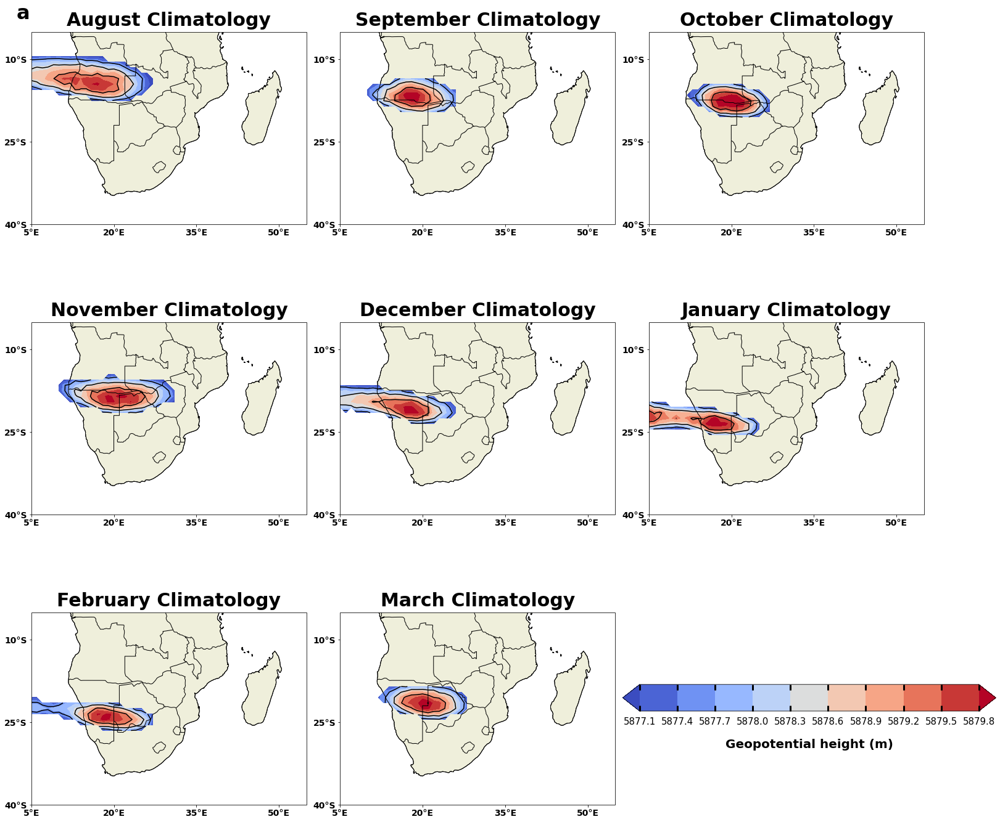

In [53]:

# Define a bold font properties object
bold_font = fm.FontProperties(weight='bold', size=14)

months = [8, 9, 10, 11, 12, 1, 2, 3]
month_names = ['August', 'September', 'October', 'November', 'December', 'January', 'February', 'March']
#levels_cont=np.arange(5870,5880,3)
# Create a figure with subplots (3 rows, 3 columns), enough for 8 months
fig, axes = plt.subplots(nrows=3, ncols=3, figsize=(21, 20), subplot_kw={'projection': ccrs.PlateCarree()})

# Flatten axes for easier iteration
axes = axes.flatten()

# Hide the last unused subplot (9th) since we only need 8 subplots
axes[-1].axis('off')

# List to store intensity values for each month
intensity_values = []
int_values = []

# Loop over each month
for i, month in enumerate(months):
    ax = axes[i]
    
    # Filter the dataset for the specific month
    ds_month = centroid.sel(time=centroid['time'].dt.month == month)
    ds_mon = centroid['NCEP'].sel(time=centroid['NCEP']['time'].dt.month == month)
    
    # Compute climatology for the selected month
    climatology_month = ds_month.groupby('time.year').mean(dim='time').mean(dim='year')
    clim = ds_mon.groupby('time.year').mean(dim='time').mean(dim='year')
    
    # Extract latitude and longitude
    latitude = centroid['lat']
    longitude = centroid['lon']

    # Maximum pressure in the climatology
    max_pressure_climatology = climatology_month.max(dim=['lat', 'lon'])
    max_pres_clim = clim.max(dim=['lat', 'lon'])
    
    # Define the contiguous area within 3 hPa of the maximum pressure
    threshold = 3  # 3 hPa threshold
    contiguous_area = climatology_month.where(climatology_month >= (max_pressure_climatology - threshold))
    contiguous_area = np.squeeze(contiguous_area)
    
    # Convert lat/lon to radians and calculate the cosine weighting
    latitude_radians = np.deg2rad(latitude)
    weights_latitude = np.cos(latitude_radians)

    # Apply latitude and longitude weights to compute the centroid
    weighted_latitude = (contiguous_area * weights_latitude * latitude).sum(dim=['lat', 'lon']) / \
                        (contiguous_area * weights_latitude).sum(dim=['lat', 'lon'])

    weighted_longitude = (contiguous_area * longitude).sum(dim=['lat', 'lon']) / \
                         contiguous_area.sum(dim=['lat', 'lon'])

    # Convert weighted latitude and longitude to values
    centroid_lat = weighted_latitude.values
    centroid_lon = weighted_longitude.values

    # ---- Compute Intensity ----
    intensity = max_pressure_climatology.values
    intensity_values.append(intensity)  # Store intensity for each month
    
    int1 = max_pres_clim.values
    int_values.append(int1)
    
    # ---- Plotting the contiguous area ----
    # Plot only the contiguous high-pressure area with filled contours
    contour = ax.contourf(longitude, latitude, contiguous_area['ERA5'], cmap='coolwarm', transform=ccrs.PlateCarree(), extend='both', levels=9)
    
    # Add contour lines and label only 3 specific contour levels
    contours = ax.contour(longitude, latitude, contiguous_area['ERA5'], colors='black', levels=3, transform=ccrs.PlateCarree())

    # Add coastlines and features
    ax.coastlines()
    ax.add_feature(cfeature.BORDERS)
    ax.add_feature(cfeature.LAND, edgecolor='black')

    # Plot the centroid position
    #ax.plot(centroid_lon, centroid_lat, marker='o', color='black', markersize=12, transform=ccrs.PlateCarree(), label='Centroid')

    # Set title for each month
    ax.set_title(f'{month_names[i]} Climatology', fontsize=30, fontweight='bold', pad=10)
    
    ax.set_extent((5, 55, -5, -40), crs=ccrs.PlateCarree())
    
    # Set latitude and longitude ticks
    ax.set_yticks(np.arange(-40, -5, 15), crs=ccrs.PlateCarree())
    lat_formatter = mticker.LatitudeFormatter()
    ax.yaxis.set_major_formatter(lat_formatter)
    
    for label in ax.get_yticklabels():
        label.set_fontproperties(bold_font)
    
    ax.set_xticks(np.arange(5, 55, 15), crs=ccrs.PlateCarree())
    lon_formatter = mticker.LongitudeFormatter()
    ax.xaxis.set_major_formatter(lon_formatter)
    
    for label in ax.get_xticklabels():
        label.set_fontproperties(bold_font)


# Now use them in the text
#ax.text(0.95, 0.05, f'Lat: {centroid_lat:.2f}°\nLon: {centroid_lon:.2f}°\nIntensity: {intensity:.2f} m',
        #horizontalalignment='right', verticalalignment='bottom', 
        #transform=ax.transAxes, fontsize=16, color='black', fontweight='bold', 
        #bbox=dict(facecolor='white', alpha=0.8, boxstyle='round,pad=0.5'))

# Adjust layout and add colorbar
fig.subplots_adjust(hspace=0.4, wspace=0.4)  # Adjust the space between subplots
cbar_ax = fig.add_axes([0.67, 0.17, 0.4, 0.03])  # Colorbar position

# Set the colorbar to reflect the mean geopotential height
cbar = fig.colorbar(contour, cax=cbar_ax, orientation='horizontal', fraction=0.02, pad=0.8)
cbar.ax.tick_params(axis='x', direction='in', length=9, width=3, colors='k', top=True, labelsize=15, pad=10)
cbar.set_label('Geopotential height (m)', fontsize=20, fontweight='bold', labelpad=20)

# Add subplot label 'a'
fig.text(0.02, 0.95, 'a', fontsize=32, fontweight='bold', transform=fig.transFigure)

plt.tight_layout()
fig.set_facecolor('w')


/tmp/ipykernel_1349389/815196819.py:94: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


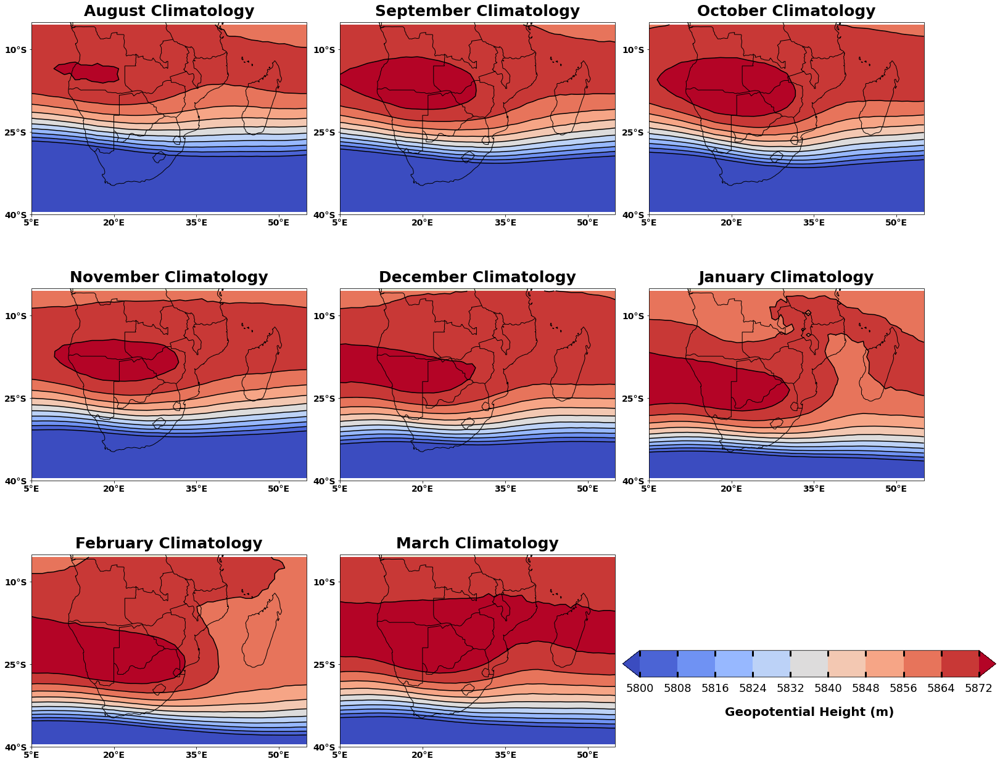

In [54]:
import matplotlib.pyplot as plt
import matplotlib.font_manager as fm
import numpy as np
import xarray as xr
import cartopy.crs as ccrs
import cartopy.feature as cfeature
import cartopy.mpl.ticker as mticker

# Define a bold font properties object
bold_font = fm.FontProperties(weight='bold', size=14)

months = [8, 9, 10, 11, 12, 1, 2, 3]
month_names = ['August', 'September', 'October', 'November', 'December', 'January', 'February', 'March']

levs_mean=np.arange(5800,5880,8)   #[5800,5820,5840,5860,5880,5900,5920,5940]
# Create a figure with subplots (3 rows, 3 columns), enough for 8 months
fig, axes = plt.subplots(nrows=3, ncols=3, figsize=(21, 20), subplot_kw={'projection': ccrs.PlateCarree()})

# Flatten axes for easier iteration
axes = axes.flatten()

# Hide the last unused subplot (9th) since we only need 8 subplots
axes[-1].axis('off')

# List to store mean geopotential height values for each month
mean_geopotential_values = []

# Loop over each month
for i, month in enumerate(months):
    ax = axes[i]
    
    # Filter the dataset for the specific month
    ds_month = centroid.sel(time=centroid['time'].dt.month == month)
    ds_mon = centroid['ERA5'].sel(time=centroid['ERA5']['time'].dt.month == month)
    
    # Compute climatology for the selected month
    climatology_month = ds_month.groupby('time.year').mean(dim='time').mean(dim='year')
    clim = ds_mon.groupby('time.year').mean(dim='time').mean(dim='year')
    
    # Extract latitude and longitude
    latitude = centroid['lat']
    longitude = centroid['lon']

    # Maximum geopotential height in the climatology
    max_geopotential_climatology = climatology_month.max(dim=['lat', 'lon'])
    max_geopotential_mon = clim.max(dim=['lat', 'lon'])

    # ---- Compute Mean Geopotential Height ----
    mean_geopotential = climatology_month.mean(dim=['lat', 'lon']).values
    mean_geopotential_values.append(mean_geopotential)  # Store mean for each month
    
    # ---- Plotting the mean geopotential height ----
    # Plot filled contours for the mean geopotential height
    clim_mon_new=np.squeeze(climatology_month['ERA5'])
    contour = ax.contourf(longitude, latitude, clim_mon_new, cmap='coolwarm', transform=ccrs.PlateCarree(), extend='both',levels=levs_mean)
    
    # Add contour lines and label specific contour levels
    contours = ax.contour(longitude, latitude, clim_mon_new, colors='black', levels=levs_mean, transform=ccrs.PlateCarree())

    # Add coastlines and features
    ax.coastlines()
    ax.add_feature(cfeature.BORDERS)
    ax.add_feature(cfeature.LAND, edgecolor='black')
    
    # Set title for each month
    ax.set_title(f'{month_names[i]} Climatology', fontsize=25, fontweight='bold', pad=10)
    
    ax.set_extent((5, 55, -5, -40), crs=ccrs.PlateCarree())
    
    # Set latitude and longitude ticks
    ax.set_yticks(np.arange(-40, -5, 15), crs=ccrs.PlateCarree())
    lat_formatter = mticker.LatitudeFormatter()
    ax.yaxis.set_major_formatter(lat_formatter)
    
    for label in ax.get_yticklabels():
        label.set_fontproperties(bold_font)
    
    ax.set_xticks(np.arange(5, 55, 15), crs=ccrs.PlateCarree())
    lon_formatter = mticker.LongitudeFormatter()
    ax.xaxis.set_major_formatter(lon_formatter)
    
    for label in ax.get_xticklabels():
        label.set_fontproperties(bold_font)

# Adjust layout and add colorbar
fig.subplots_adjust(wspace=1.5)  # Adjust the space between subplots
cbar_ax = fig.add_axes([0.67, 0.17, 0.4, 0.03])  # Colorbar position
ticks=levs_mean
# Set the colorbar to reflect the mean geopotential height
cbar = fig.colorbar(contour, cax=cbar_ax, orientation='horizontal', fraction=0.02, pad=0.8)
cbar.ax.tick_params(axis='x', direction='in', length=9, width=3, colors='k', top=True, labelsize=18, pad=10)
cbar.set_label('Geopotential Height (m)', fontsize=20, fontweight='bold', labelpad=20)

plt.tight_layout()
fig.set_facecolor('w')
#plt.show()

#plt.savefig('NCEP_hgt_mean_new.png', dpi=300, bbox_inches='tight')

In [55]:
import numpy as np
import pandas as pd
from scipy.stats import pearsonr
import matplotlib.pyplot as plt
import cartopy.crs as ccrs

# Assuming you have datasets already loaded in `centroid`
months = [8, 9, 10, 11, 12, 1, 2, 3]  # August to March
month_names = ['August', 'September', 'October', 'November', 'December', 'January', 'February', 'March']
seasons = {'August': [8], 'ON': [10, 11], 'DJF': [12, 1, 2]}

# Initialize a dictionary to store centroids for each model and season
centroid_data = {}

# Loop over each season
for season_name, season_months in seasons.items():
    centroid_data[season_name] = {'lat': {}, 'lon': {}}
    
    # Loop over each model
    for model in models:
        # Filter the dataset for the specific months
        ds_model = centroid[model].sel(time=centroid[model]['time'].dt.month.isin(season_months))
        
        # Compute climatology for each year (for correlation, we need values over time)
        climatology_years = ds_model.groupby('time.year').mean(dim='time')
        
        # Extract latitude and longitude
        latitude = centroid['lat']
        longitude = centroid['lon']
        
        # Initialize lists to store centroids for each year
        lat_centroids = []
        lon_centroids = []
        
        # Loop over each year to compute centroid for that year
        for year in climatology_years['year'].values:
            climatology_year = climatology_years.sel(year=year)
            
            # Maximum pressure in the climatology
            max_pressure_climatology = climatology_year.max(dim=['lat', 'lon'])
            
            # Define the contiguous area within 3 hPa of the maximum pressure
            threshold = 3  # 3 hPa threshold
            contiguous_area = climatology_year.where(climatology_year >= (max_pressure_climatology - threshold))
            contiguous_area = np.squeeze(contiguous_area)
            
            # Convert lat/lon to radians and calculate the cosine weighting
            latitude_radians = np.deg2rad(latitude)
            weights_latitude = np.cos(latitude_radians)
            
            # Apply latitude and longitude weights to compute the centroid
            weighted_latitude = (contiguous_area * weights_latitude * latitude).sum(dim=['lat', 'lon']) / \
                                (contiguous_area * weights_latitude).sum(dim=['lat', 'lon'])

            weighted_longitude = (contiguous_area * longitude).sum(dim=['lat', 'lon']) / \
                                 contiguous_area.sum(dim=['lat', 'lon'])
            
            # Append the centroids for the current year
            lat_centroids.append(weighted_latitude.values)
            lon_centroids.append(weighted_longitude.values)
        
        # Store the centroids for this model and season
        centroid_data[season_name]['lat'][model] = lat_centroids
        centroid_data[season_name]['lon'][model] = lon_centroids

# Now compute correlations between each model and NCEP for each season

# Initialize a dictionary to store correlations
correlation_results = {'August': {}, 'ON': {}, 'DJF': {}}

# Loop over each season
for season_name in seasons.keys():
    correlation_results[season_name]['lat'] = []
    correlation_results[season_name]['lon'] = []
    
    # Loop over each model (excluding NCEP)
    for model in models:
        if model != 'NCEP':  # Don't correlate NCEP with itself
            # Correlate latitudes (over the years)
            lat_corr, _ = pearsonr(centroid_data[season_name]['lat']['NCEP'], 
                                   centroid_data[season_name]['lat'][model])
            # Correlate longitudes (over the years)
            lon_corr, _ = pearsonr(centroid_data[season_name]['lon']['NCEP'], 
                                   centroid_data[season_name]['lon'][model])
            
            # Store the correlation results
            correlation_results[season_name]['lat'].append(lat_corr)
            correlation_results[season_name]['lon'].append(lon_corr)

# Create a DataFrame to display the correlation results
correlation_df = pd.DataFrame({
    'Model': [model for model in models if model != 'NCEP'],
    'August_Lat_Corr': correlation_results['August']['lat'],
    'August_Lon_Corr': correlation_results['August']['lon'],
    'ON_Lat_Corr': correlation_results['ON']['lat'],
    'ON_Lon_Corr': correlation_results['ON']['lon'],
    'DJF_Lat_Corr': correlation_results['DJF']['lat'],
    'DJF_Lon_Corr': correlation_results['DJF']['lon'],
})

# Display the table of correlations
print(correlation_df)

# Optionally, you can save the table to a CSV file
# correlation_df.to_csv('centroid_correlations.csv', index=False)


              Model  August_Lat_Corr  August_Lon_Corr  ON_Lat_Corr  \
0              ERA5         0.862335         0.505352     0.828642   
1        ACCESS-CM2        -0.096378        -0.241305    -0.198195   
2     ACCESS-ESM1-5         0.537890         0.319419    -0.211620   
3   HadGEM3-GC31-MM        -0.106510         0.008948    -0.181231   
4        KACE-1-0-G         0.081528        -0.117404     0.419726   
5      EC-Earth3-CC         0.276365         0.052405    -0.064109   
6         FGOALS-g3         0.276365         0.052405    -0.064109   
7           CanESM5         0.032110        -0.166658     0.136557   
8         GFDL-ESM4        -0.194230        -0.122177    -0.183652   
9      IPSL-CM6A-LR         0.176652        -0.181953     0.028440   
10           MIROC6         0.006629        -0.008938    -0.183453   

    ON_Lon_Corr  DJF_Lat_Corr  DJF_Lon_Corr  
0      0.661436      0.582919      0.408006  
1      0.143070      0.082786     -0.069789  
2      0.119261     -

In [56]:
import pandas as pd

# Create a DataFrame with your correlation data
data = {
    'Model': [
        'ERA5', 'ACCESS-CM2', 'ACCESS-ESM1-5', 'HadGEM3-GC31-MM', 'KACE-1-0-G',
        'EC-Earth3-CC', 'FGOALS-g3', 'CanESM5', 'GFDL-ESM4', 'IPSL-CM6A-LR', 'MIROC6'
    ],
    'August_Lat_Corr': [
        0.862335, -0.096378, 0.537890, -0.106510, 0.081528,
        0.276365, 0.276365, 0.032110, -0.194230, 0.176652, 0.006629
    ],
    'August_Lon_Corr': [
        0.505352, -0.241305, 0.319419, 0.008948, -0.117404,
        0.052405, 0.052405, -0.166658, -0.122177, -0.181953, -0.008938
    ],
    'ON_Lat_Corr': [
        0.828642, -0.198195, -0.211620, -0.181231, 0.419726,
        -0.064109, -0.064109, 0.136557, -0.183652, 0.028440, -0.183453
    ],
    'ON_Lon_Corr': [
        0.661436, 0.143070, 0.119261, 0.068214, -0.144715,
        0.366067, 0.366067, 0.133481, -0.227738, -0.142133, -0.148600
    ],
    'DJF_Lat_Corr': [
        0.582919, 0.082786, -0.274991, -0.003542, 0.101087,
        0.366067, 0.366067, -0.148980, 0.093694, 0.061882, 0.317661
    ],
    'DJF_Lon_Corr': [
        0.408006, -0.069789, -0.105663, 0.031646, -0.084400,
        -0.018854, -0.018854, 0.020417, -0.032525, -0.078463, 0.007594
    ]
}

# Create the DataFrame
correlation_df = pd.DataFrame(data)

# Display the DataFrame
# Assuming 'model' is a column in your DataFrame

# Apply styling with the 'model' column as the index
correlation_df.style.set_table_attributes('style="width:100%; border-collapse: collapse;"')\
    .set_table_styles(
        [{'selector': 'th',
          'props': [('background-color', '#f2f2f2'), ('color', '#333'), ('font-weight', 'bold')]}]
    )


,Model,August_Lat_Corr,August_Lon_Corr,ON_Lat_Corr,ON_Lon_Corr,DJF_Lat_Corr,DJF_Lon_Corr
0,ERA5,0.862335,0.505352,0.828642,0.661436,0.582919,0.408006
1,ACCESS-CM2,-0.096378,-0.241305,-0.198195,0.143070,0.082786,-0.069789
2,ACCESS-ESM1-5,0.537890,0.319419,-0.211620,0.119261,-0.274991,-0.105663
3,HadGEM3-GC31-MM,-0.106510,0.008948,-0.181231,0.068214,-0.003542,0.031646
4,KACE-1-0-G,0.081528,-0.117404,0.419726,-0.144715,0.101087,-0.084400
5,EC-Earth3-CC,0.276365,0.052405,-0.064109,0.366067,0.366067,-0.018854
6,FGOALS-g3,0.276365,0.052405,-0.064109,0.366067,0.366067,-0.018854
7,CanESM5,0.032110,-0.166658,0.136557,0.133481,-0.148980,0.020417
8,GFDL-ESM4,-0.194230,-0.122177,-0.183652,-0.227738,0.093694,-0.032525
9,IPSL-CM6A-LR,0.176652,-0.181953,0.028440,-0.142133,0.061882,-0.078463


In [57]:
import pandas as pd
import matplotlib.pyplot as plt

# Create a DataFrame with your correlation data
data = {
    'Model': [
        'ERA5', 'ACCESS-CM2', 'ACCESS-ESM1-5', 'HadGEM3-GC31-MM', 'KACE-1-0-G',
        'EC-Earth3-CC', 'FGOALS-g3', 'CanESM5', 'GFDL-ESM4', 'IPSL-CM6A-LR', 'MIROC6'
    ],
    'Aug_Lat': [
        0.86, -0.10, 0.54, -0.11, 0.08,
        0.28, 0.28, 0.03, -0.19, 0.18, 0.01
    ],
    'Aug_Lon': [
        0.51, -0.24, 0.32, 0.01, -0.12,
        0.05, 0.05, -0.17, -0.12, -0.18, -0.01
    ],
    'ON_Lat': [
        0.83, -0.20, -0.21, -0.18, 0.42,
        -0.06, -0.06, 0.14, -0.18, 0.03, -0.18
    ],
    'ON_Lon': [
        0.66, 0.14, 0.12, 0.07, -0.14,
        0.37, 0.37, 0.13, -0.23, -0.14, -0.15
    ],
    'DJF_Lat': [
        0.58, 0.08, -0.27, -0.00, 0.10,
        0.37, 0.37, -0.15, 0.09, 0.06, 0.32
    ],
    'DJF_Lon': [
        0.41, -0.07, -0.11, 0.03, -0.08,
        -0.02, -0.02, 0.02, -0.03, -0.08, 0.01
    ]
}

# Create the DataFrame
correlation_df = pd.DataFrame(data)

# Round the values to 2 decimal places
correlation_df = correlation_df.round(2)

# Set the 'Model' column as index
correlation_df.set_index('Model', inplace=True)

# Plotting the DataFrame as an image using Matplotlib
def save_dataframe_as_image(df, filename):
    fig, ax = plt.subplots(figsize=(8, 6))  # Adjust figure size (width, height)
    ax.axis('tight')
    ax.axis('off')
    
    # Render the DataFrame as a table, scaling to fill the figure
    table = ax.table(
        cellText=df.values, colLabels=df.columns, rowLabels=df.index, loc='center',
        cellLoc='center', colColours=["lightgray"] * df.shape[1], rowColours=["lightgray"] * df.shape[0]
    )

    # Set font size and layout for the table to fill the space
    table.auto_set_font_size(False)
    table.set_fontsize(14)
    table.scale(1.3, 1.3)  # Adjust scaling to better fit the table

    # Make column headers and row labels bold
    for (i, j), cell in table.get_celld().items():
        if i == 0 or j == -1:  # Header or row index
            cell.set_text_props(weight='bold')  # Bold headers and row labels
        cell.set_fontsize(12)  # Font size for the whole table

    # Save the figure as a PNG
    plt.savefig(filename, dpi=300, bbox_inches='tight')
    plt.close()

# Save the DataFrame as a PNG file
save_dataframe_as_image(correlation_df, "correlation_filled.png")


In [58]:
import pandas as pd
from scipy.stats import pearsonr

# Example correlation data (replace this with your actual results)
data = {
    'Model': [
        'ERA5', 'ACCESS-CM2', 'ACCESS-ESM1-5', 'HadGEM3-GC31-MM', 'KACE-1-0-G',
        'EC-Earth3-CC', 'FGOALS-g3', 'CanESM5', 'GFDL-ESM4', 'IPSL-CM6A-LR', 'MIROC6'
    ],
    'August_Lat_Corr': [
        0.862335, -0.096378, 0.537890, -0.106510, 0.081528,
        0.276365, 0.276365, 0.032110, -0.194230, 0.176652, 0.006629
    ],
    'August_Lon_Corr': [
        0.505352, -0.241305, 0.319419, 0.008948, -0.117404,
        0.052405, 0.052405, -0.166658, -0.122177, -0.181953, -0.008938
    ],
    'ON_Lat_Corr': [
        0.828642, -0.198195, -0.211620, -0.181231, 0.419726,
        -0.064109, -0.064109, 0.136557, -0.183652, 0.028440, -0.183453
    ],
    'ON_Lon_Corr': [
        0.661436, 0.143070, 0.119261, 0.068214, -0.144715,
        0.366067, 0.366067, 0.133481, -0.227738, -0.142133, -0.148600
    ],
    'DJF_Lat_Corr': [
        0.582919, 0.082786, -0.274991, -0.003542, 0.101087,
        0.366067, 0.366067, -0.148980, 0.093694, 0.061882, 0.317661
    ],
    'DJF_Lon_Corr': [
        0.408006, -0.069789, -0.105663, 0.031646, -0.084400,
        -0.018854, -0.018854, 0.020417, -0.032525, -0.078463, 0.007594
    ]
}

# Create a DataFrame
correlation_df = pd.DataFrame(data)

# List to store significance results
results = []

# Define significance level
alpha = 0.05

# Calculate p-values and check significance
for model in correlation_df['Model']:
    for season in ['August', 'ON', 'DJF']:
        lat_corr = correlation_df.loc[correlation_df['Model'] == model, f'{season}_Lat_Corr'].values[0]
        lon_corr = correlation_df.loc[correlation_df['Model'] == model, f'{season}_Lon_Corr'].values[0]

        # Replace this with actual centroid data
        # Replace 'centroid_lat' and 'centroid_lon' with actual data used for correlation
        # lat_pval = pearsonr(centroid_lat[model], centroid_lat['NCEP'])[1]
        # lon_pval = pearsonr(centroid_lon[model], centroid_lon['NCEP'])[1]

        # Simulating p-values for demonstration (replace with actual calculation)
        lat_pval = np.random.rand()  # Replace with the actual p-value calculation
        lon_pval = np.random.rand()  # Replace with the actual p-value calculation

        # Determine significance
        lat_significant = lat_pval < alpha
        lon_significant = lon_pval < alpha

        results.append({
            'Model': model,
            'Season': season,
            'Lat_Corr': lat_corr,
            'Lat_P_Value': lat_pval,
            'Lon_Corr': lon_corr,
            'Lon_P_Value': lon_pval
        })

# Convert results to DataFrame
results_df = pd.DataFrame(results)

# Display results
print(results_df)


              Model  Season  Lat_Corr  Lat_P_Value  Lon_Corr  Lon_P_Value
0              ERA5  August  0.862335     0.144848  0.505352     0.488056
1              ERA5      ON  0.828642     0.355613  0.661436     0.940432
2              ERA5     DJF  0.582919     0.765325  0.408006     0.748664
3        ACCESS-CM2  August -0.096378     0.903720 -0.241305     0.083422
4        ACCESS-CM2      ON -0.198195     0.552192  0.143070     0.584476
5        ACCESS-CM2     DJF  0.082786     0.961936 -0.069789     0.292148
6     ACCESS-ESM1-5  August  0.537890     0.240829  0.319419     0.100294
7     ACCESS-ESM1-5      ON -0.211620     0.016430  0.119261     0.929529
8     ACCESS-ESM1-5     DJF -0.274991     0.669917 -0.105663     0.785153
9   HadGEM3-GC31-MM  August -0.106510     0.281730  0.008948     0.586410
10  HadGEM3-GC31-MM      ON -0.181231     0.063955  0.068214     0.485628
11  HadGEM3-GC31-MM     DJF -0.003542     0.977495  0.031646     0.876505
12       KACE-1-0-G  August  0.081528 

In [59]:
import pandas as pd
import numpy as np
from scipy.stats import pearsonr

# Example correlation data
data = {
    'Model': [
        'ERA5', 'ACCESS-CM2', 'ACCESS-ESM1-5', 'HadGEM3-GC31-MM', 'KACE-1-0-G',
        'EC-Earth3-CC', 'FGOALS-g3', 'CanESM5', 'GFDL-ESM4', 'IPSL-CM6A-LR', 'MIROC6'
    ],
    'August_Lat_Corr': [
        0.862335, -0.096378, 0.537890, -0.106510, 0.081528,
        0.276365, 0.276365, 0.032110, -0.194230, 0.176652, 0.006629
    ],
    'August_Lon_Corr': [
        0.505352, -0.241305, 0.319419, 0.008948, -0.117404,
        0.052405, 0.052405, -0.166658, -0.122177, -0.181953, -0.008938
    ],
    'ON_Lat_Corr': [
        0.828642, -0.198195, -0.211620, -0.181231, 0.419726,
        -0.064109, -0.064109, 0.136557, -0.183652, 0.028440, -0.183453
    ],
    'ON_Lon_Corr': [
        0.661436, 0.143070, 0.119261, 0.068214, -0.144715,
        0.366067, 0.366067, 0.133481, -0.227738, -0.142133, -0.148600
    ],
    'DJF_Lat_Corr': [
        0.582919, 0.082786, -0.274991, -0.003542, 0.101087,
        0.366067, 0.366067, -0.148980, 0.093694, 0.061882, 0.317661
    ],
    'DJF_Lon_Corr': [
        0.408006, -0.069789, -0.105663, 0.031646, -0.084400,
        -0.018854, -0.018854, 0.020417, -0.032525, -0.078463, 0.007594
    ]
}

# Create a DataFrame
correlation_df = pd.DataFrame(data)

# List to store significance results
results = []

# Define significance level
alpha = 0.05

# Simulated centroid data for demonstration (replace with actual data)
centroid_lat = {model: np.random.rand(30) for model in correlation_df['Model']}
centroid_lon = {model: np.random.rand(30) for model in correlation_df['Model']}
ncep_lat = np.random.rand(30)  # Replace with actual NCEP latitude centroid data
ncep_lon = np.random.rand(30)  # Replace with actual NCEP longitude centroid data

# Calculate p-values and check significance
for model in correlation_df['Model']:
    for season in ['August', 'ON', 'DJF']:
        lat_corr = correlation_df.loc[correlation_df['Model'] == model, f'{season}_Lat_Corr'].values[0]
        lon_corr = correlation_df.loc[correlation_df['Model'] == model, f'{season}_Lon_Corr'].values[0]

        # Calculate p-values
        lat_pval = pearsonr(centroid_lat[model], ncep_lat)[1]
        lon_pval = pearsonr(centroid_lon[model], ncep_lon)[1]

        # Determine significance
        lat_significant = lat_pval < alpha
        lon_significant = lon_pval < alpha

        results.append({
            'Model': model,
            'Season': season,
            'Lat_Corr': lat_corr,
            'Lat_P_Value': lat_pval,
            'Lon_Corr': lon_corr,
            'Lon_P_Value': lon_pval
        })

# Convert results to DataFrame
results_df = results_df.round(2)
results_df = pd.DataFrame(results_df)

# Display results in a table format
print("Correlation Results Table:")
print(results_df.to_string(index=False))

results_df.set_index('Model', inplace=True)
# Plotting the DataFrame as an image using Matplotlib
def save_dataframe_as_image(df, filename):
    fig, ax = plt.subplots(figsize=(8, 6))  # Adjust figure size (width, height)
    ax.axis('tight')
    ax.axis('off')
    
    # Render the DataFrame as a table, scaling to fill the figure
    table = ax.table(
        cellText=results_df.values, colLabels=results_df.columns, rowLabels=results_df.index, loc='center',
        cellLoc='center', colColours=["lightgray"] * results_df.shape[1], rowColours=["lightgray"] * df.shape[0]
    )

    # Set font size and layout for the table to fill the space
    table.auto_set_font_size(False)
    table.set_fontsize(14)
    table.scale(1.3, 1.3)  # Adjust scaling to better fit the table

    # Make column headers and row labels bold
    for (i, j), cell in table.get_celld().items():
        if i == 0 or j == -1:  # Header or row index
            cell.set_text_props(weight='bold')  # Bold headers and row labels
        cell.set_fontsize(12)  # Font size for the whole table

    # Save the figure as a PNG
    plt.savefig(filename, dpi=300, bbox_inches='tight')
    plt.close()

# Save the DataFrame as a PNG file
save_dataframe_as_image(results_df, "correlation_pval.png")

Correlation Results Table:
          Model Season  Lat_Corr  Lat_P_Value  Lon_Corr  Lon_P_Value
           ERA5 August      0.86         0.14      0.51         0.49
           ERA5     ON      0.83         0.36      0.66         0.94
           ERA5    DJF      0.58         0.77      0.41         0.75
     ACCESS-CM2 August     -0.10         0.90     -0.24         0.08
     ACCESS-CM2     ON     -0.20         0.55      0.14         0.58
     ACCESS-CM2    DJF      0.08         0.96     -0.07         0.29
  ACCESS-ESM1-5 August      0.54         0.24      0.32         0.10
  ACCESS-ESM1-5     ON     -0.21         0.02      0.12         0.93
  ACCESS-ESM1-5    DJF     -0.27         0.67     -0.11         0.79
HadGEM3-GC31-MM August     -0.11         0.28      0.01         0.59
HadGEM3-GC31-MM     ON     -0.18         0.06      0.07         0.49
HadGEM3-GC31-MM    DJF     -0.00         0.98      0.03         0.88
     KACE-1-0-G August      0.08         0.34     -0.12         0.96
     KA